# Modulación LoRa (FSCM)

Modelo en Python de la modulación LoRa basado en el análisis de
L. Vangelista, ["Frequency Shift Chirp Modulation: The LoRa Modulation"](https://doi.org/10.1109/LSP.2017.2762960),
*IEEE Signal Processing Letters*, vol. 24, no. 12, pp. 1818–1821, dic. 2017.

| Autor                | Email                             |
|----------------------|-----------------------------------|
| Badenes, Tomás       | tomasbadenes@mi.unc.edu.ar        |
| Pineda, Juan Ignacio | juan.ignacio.pineda@mi.unc.edu.ar |
| Doniquian, Pedro     | pedoniquian@mi.unc.edu.ar         |

## Modelo del sistema

*TODO(b-Tomas): diagrama de bloques*

In [1]:
# Todos los imports van acá
import time
import timeit
from collections.abc import Callable

import matplotlib.pyplot as plt
import numpy as np
from math import comb, factorial, sqrt

## Transmisión

El módulo transmisor se compone de dos partes: el codificador y el conformador de onda.

### Codificador

Se considera como objetivo transmitir y recibir un conjunto de bits. Para esto, se debe convertir el conjunto de bits en símbolos.

El bloque de parámetros ya define los símbolos a enviar en la lista `symbols`, por lo que primero se retrocederá un paso para convetirlos en el conjunto de bits a enviar. Luego, `encoder()` tomará el conjunto de bits y los convertirá en símbolos.

Cada símbolo se genera con un vector $w(nT_s)$ de $SF$ bits de acuerdo a Ec. 1:

$$
s(nT_s) = \sum_{h=0}^{SF-1} w(nT_s)_h \cdot 2^h
$$

$w_0$ es el bit menos significativo. El flujo de bits se corta en grupos de $SF$ bits, un grupo por símbolo.

In [2]:
def encoder(bits: np.ndarray, SF: int) -> np.ndarray:
    """Convierte un conjunto de bits en símbolos.

    Organiza `bits` en grupos $w(nT_s)$ de `SF` bits y los convierte a símbolos.

    Args:
        bits (np.ndarray): Conjunto de bits a transmitir.
        SF (int): Spreading factor.

    Returns:
        np.ndarray: Conjunto de símbolos a transmitir.
    """

    # Validar la forma del vector de bits a enviar
    assert bits.size % SF == 0, "El número de bits debe ser múltiplo de SF"

    # Reorganizar los bits en grupos de SF bits
    # El resultado es un arreglo de forma (N, SF) donde N es el número de símbolos.
    # Cada símbolo es un vector equivalente a $w(nT_s)$
    W = bits.reshape(-1, SF)

    # Secuencia h = 0..SF-1
    h = np.arange(SF)

    # Convertir cada grupo de SF bits a un símbolo
    # 2**h produce un vector de potencias de 2: [1, 2, 4, ..., 2**(SF-1)]
    # W @ 2**h realiza el producto matricial, sumando los productos de cada bit por su correspondiente potencia de 2.
    return W @ 2**h

In [3]:
# Tests
assert np.array_equal(encoder(np.array([0, 0, 0, 1, 0, 0, 0]), 7), np.array([8]))
assert np.array_equal(
    encoder(np.array([0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]), 7), np.array([8, 127])
)

### Conformador de onda

Dado el vector de símbolos $s(nT_s)$, el conformador de onda genera la señal modulada de acuerdo a Ec. 2 para cada símbolo $n$ y cada chip $k = 0, \dots, 2^{SF}-1$:

$$
c(nT_s + kT) = \frac{1}{\sqrt{2^{SF}}}\, e^{\,j2\pi \left[(s(nT_s) + k) \bmod 2^{SF}\right] kT \frac{B}{2^{SF}}}
$$

El resultado $c(nT_s + kT)$ es un vector complejo unidimensional de $2^{SF}$ chips por cada símbolo $n$.

In [4]:
def modulator(symbols: np.ndarray, SF: int, B: float) -> np.ndarray:
    """Genera la forma de onda FSCM para una secuencia de símbolos.

    Muestrea a k = 0..2**SF-1 chips por cada símbolo n.

    Args:
        symbols (np.ndarray): Conjunto de símbolos $s(nT_s)$ a transmitir. 0 <= s < 2**SF.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.

    Returns:
        np.ndarray: Señal modulada (compleja) en el dominio del tiempo.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Tiempo de chip
    T = 1 / B

    # Convertir s a un vector de forma (N, 1) para poder sumarle k
    s = symbols.reshape(-1, 1)  # Vector columna de símbolos

    # Vector de chips k = 0..M-1
    k = np.arange(M)  # Vector fila de chips

    # Frecuencia instantanea de la señal modulada: f(k) = (s + k) mod M * B / M
    # Es el exponente en la Ec. 2, sin el muestreo kT
    f = ((s + k) % M) * B / M

    # c[n, k] = c(nT_s + kT). Vector de forma (N, M) donde N es el número de símbolos y M es el número de chips por símbolo.
    c = np.exp(1j * 2 * np.pi * f * k * T) / np.sqrt(M)

    return c.ravel()  # Aplanar a un vector unidimensional de chips

#### Análisis de la señal modulada

Antes de continuar con la transmisión, se analiza la forma y comportamiento de la señal modulada en tiempo y en frecuencia en una configuración con *Spreading Factor* de 7.

In [5]:
SF = 7
symbols = np.array([0, 32, 80])
B = 125e3  # Ancho de banda de 125 kHz

c = modulator(symbols, SF, B)

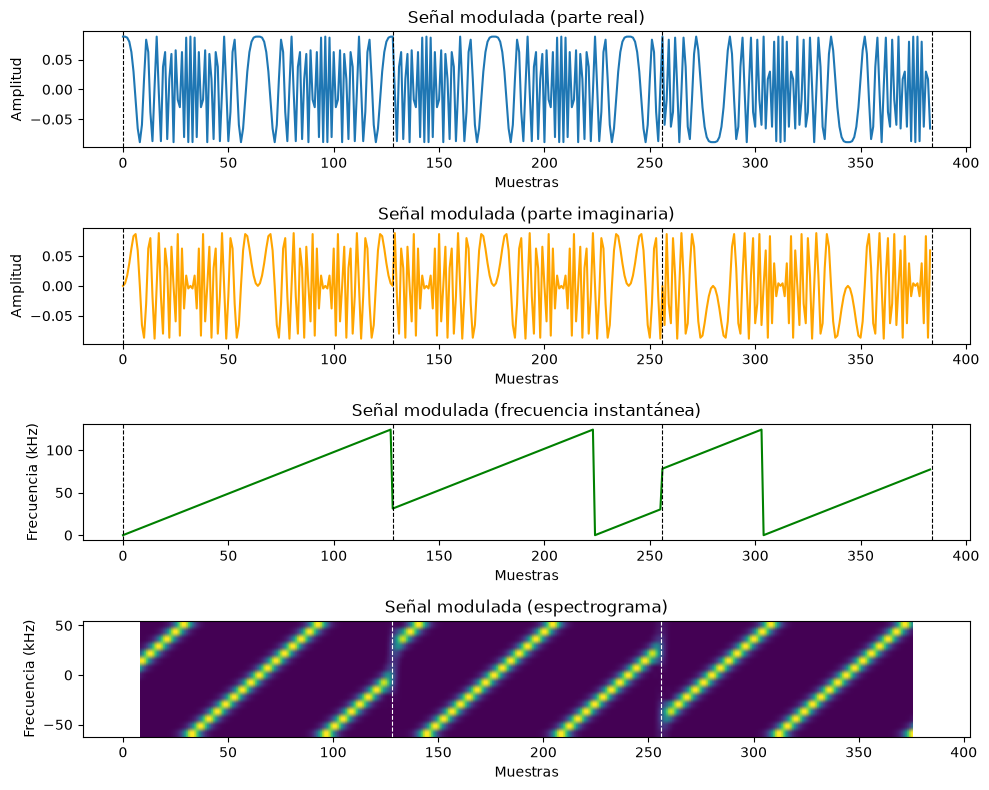

In [6]:
# Señal real e imaginaria de la señal modulada en el tiempo
plt.figure(figsize=(10, 8))
plt.subplot(4, 1, 1)
plt.plot(np.real(c), label="Real")
plt.title("Señal modulada (parte real)")
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.subplot(4, 1, 2)
plt.plot(np.imag(c), label="Imag", color="orange")
plt.title("Señal modulada (parte imaginaria)")
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
# Frecuencia instantánea en el tiempo: f(k) = (s + k) mod M * B / M
plt.subplot(4, 1, 3)
k = np.arange(2**SF)
f = ((symbols.reshape(-1, 1) + k) % 2**SF) * B / 2**SF
plt.plot(f.ravel() / 1e3, color="green")
plt.title("Señal modulada (frecuencia instantánea)")
plt.xlabel("Muestras")
plt.ylabel("Frecuencia (kHz)")
# Espectrograma: frecuencia en el tiempo estimada a partir de la señal c
plt.subplot(4, 1, 4)
N = 16  # muestras por ventana de la FFT
# xextent: eje x en muestras, como los otros gráficos (cada ventana se ubica en su centro)
plt.specgram(
    c,
    NFFT=N,
    noverlap=N - 1,
    Fs=B / 1e3,
    sides="twosided",
    scale="linear",
    xextent=(N / 2, c.size - N / 2),
)
plt.title("Señal modulada (espectrograma)")
plt.xlabel("Muestras")
plt.ylabel("Frecuencia (kHz)")
# Separación entre símbolos: un símbolo (Ts) son 2**SF muestras
for ax in plt.gcf().axes:
    for n in range(len(symbols) + 1):
        # Blanco sobre el espectrograma (fondo oscuro), negro en el resto
        ax.axvline(n * 2**SF, color="w" if ax.images else "k", ls="--", lw=0.8)
plt.tight_layout()
plt.show()

**Dominio del tiempo**:
- La señal es una exponencial compleja de frecuencia variable, conocida como *chirp*.
- La parte real es una onda cosenoidal de frecuencia creciente, mientras que la parte imaginaria es una onda senoide de frecuencia creciente.

**Frecuencia instantánea**:
- El gráfico muestra la frecuencia instantánea de la señal de la Ec. 2. con fines pedagógicos.
- De acuerdo con lo que se puede ver en las ondas de la parte real e imaginaria, la frecuencia instantánea es una función lineal del tiempo, que aumenta de 0 a $B$ en el intervalo de tiempo $T_s$.
- La frecuencia instantánea inicial para cada símbolo es distinta de acuerdo a $f_0 = \frac{B}{2^{SF}} s(nT_s)$.

**Espectrograma:**
- Muestra la frecuencia real de $c$.

## Recepción

El módulo receptor se compone de un demodulador y un decodificador.

### Demodulación

Se conoce a esta etapa como *n-Tuple former* o conformador de tuplas, y genera símbolos a partir de la señal recibida, la cual es un vector complejo unidimensional de $2^{SF}$ chips por cada símbolo $n$.

Se analizará primero demodulando la señal modulada, y luego sumándole ruido blanco gaussiano aditivo (AWGN) para simular la transmisión por un canal ruidoso.

El proceso de demodulación de forma computacionalmente eficiente se describe en Ec. 16 como la proyección de la señal recibida $r(nT_s + kT)$ sobre un conjunto de *chirps* ortogonales $c|_{q}$:

$$
\langle r, c|_{s=q} \rangle = \sum_{k=0}^{2^{SF}-1} r(nT_s + kT)\, e^{-j2\pi \frac{k^2}{2^{SF}}} \cdot \frac{1}{\sqrt{2^{SF}}}\, e^{-j2\pi \frac{qk}{2^{SF}}}
$$

Se puede interpretar como la correlación entre la señal recibida y todos los *chirps* posibles, siendo el *chirp* que maximiza la proyección el símbolo recibido.

El término $e^{-j2\pi \frac{k^2}{2^{SF}}}$ se conoce como *down-chirp*. El resultado $d(nT_s + kT) = r(nT_s + kT) \cdot e^{-j2\pi \frac{k^2}{2^{SF}}}$ es una exponencial compleja de frecuencia constante igual a la frecuencia inicial del símbolo recibido. Se utiliza la transformada rápida de Fourier (FFT).

Luego, la transformada de Fourier de $d(nT_s + kT)$ resultará en un impulso desplazado en el índice de la frecuencia correspondiente a la frecuencia del símbolo recibido.


In [7]:
def demodulator(r: np.ndarray, SF: int) -> np.ndarray:
    """Demodula una señal LoRa de Spreading-Factor SF según Ec. 16.

    Args:
        r: Señal LoRa modulada recibida.
        SF: Spreading-Factor.

    Returns:
        np.ndarray: Arreglo unidimensional de símbolos demodulados.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Validar el largo del array
    assert r.size % M == 0, "El número de chirps debe ser múltiplo de SF"

    # Convertir s a un vector de forma (N, M): R[n, k] = r(nT_s + kT)
    R = r.reshape(-1, M)  # Vector columna de símbolos

    # Vector de chips k = 0..M-1
    k = np.arange(M)  # Vector fila de chips

    # Obtener d(nT_s + kT) = r(nT_s + kT) * downchirp
    downchirp = np.exp(-1j * 2 * np.pi * k**2 / M)
    d = R * downchirp

    # Transformada de Fourier (discreta) de cada fila (símbolo)
    # norm="ortho" normaliza la FFT para que la salida sea unitiaria (conserve la energía de la señal)
    # equivalente a aplicar el factor 1/sqrt(M) de Ec. 16 a la salida de la FFT
    D = np.fft.fft(d, norm="ortho")

    # Decidir el símbolo demodulado como el índice del máximo de la FFT
    return np.argmax(np.abs(D) ** 2, axis=1)

In [8]:
# Tests
assert np.array_equal(demodulator(modulator(symbols, SF, B), SF), symbols)

#### Visualización del proceso de decisión

Para cada símbolo recibido se obtiene la frecuencia inicial del *chirp* recibido mediante el *down-chirp* y la FFT. La transformada de Fourier de $d(nT_s + kT)$ (una exponencial compleja de frecuencia constante) resultará en un impulso desplazado en el índice de la frecuencia correspondiente a la frecuencia del símbolo recibido.

Mas adelante se analizará la decisión en un canal ruidoso.

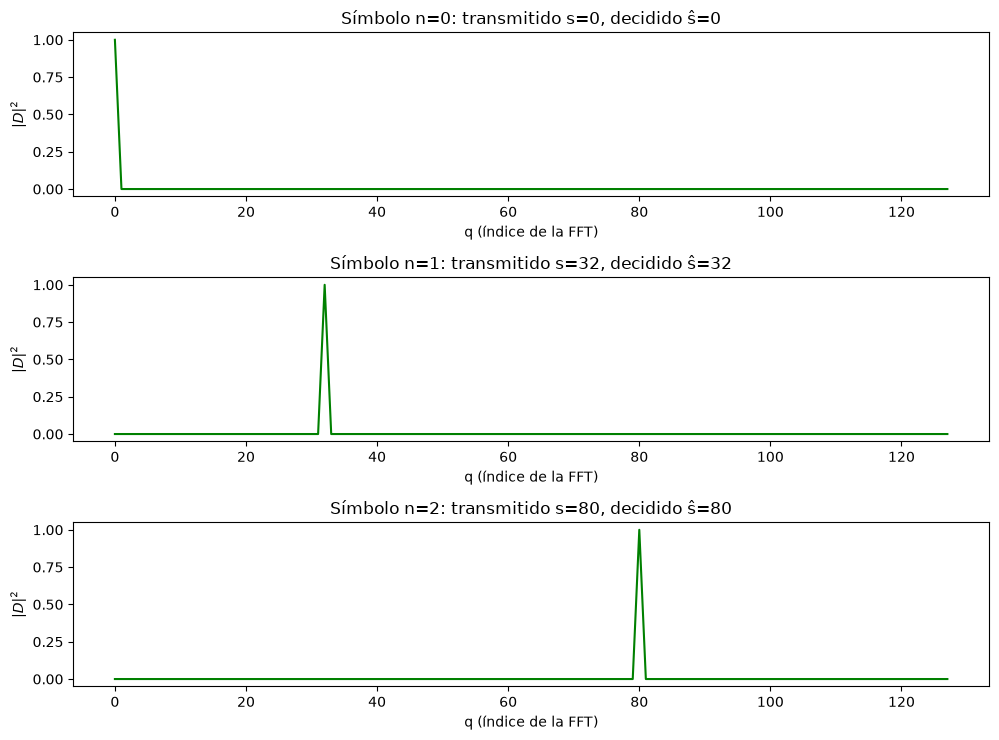

In [9]:
# Repetir los pasos de demodulator para ver la salida de la FFT antes de decidir
M: int = 2**SF
k = np.arange(M)
# Multiplicar cada símbolo recibido por el down-chirp
d = c.reshape(-1, M) * np.exp(-1j * 2 * np.pi * k**2 / M)
# FFT de cada símbolo
D = np.fft.fft(d, norm="ortho")
# Decisión: índice del máximo de |D|^2
symbols_rx = demodulator(c, SF)

plt.figure(figsize=(10, 2.5 * len(symbols)))
for n in range(len(symbols)):
    plt.subplot(len(symbols), 1, n + 1)
    plt.plot(np.abs(D[n]) ** 2, color="green")
    plt.title(f"Símbolo n={n}: transmitido s={symbols[n]}, decidido ŝ={symbols_rx[n]}")
    plt.xlabel("q (índice de la FFT)")
    plt.ylabel("$|D|^2$")
plt.tight_layout()
plt.show()

### Decodificación

Se descompone cada símbolo en un arreglo de $SF$ bits de acuerdo a Ec. 1.

In [10]:
def decoder(symbols: np.ndarray, SF: int) -> np.ndarray:
    """Convierte un conjunto de símbolos en bits.

    Descompone cada símbolo en un arreglo de `SF` bits de acuerdo a Ec. 1.

    Args:
        symbols (np.ndarray): Conjunto de símbolos a decodificar.
        SF (int): Spreading factor.

    Returns:
        np.ndarray: Conjunto de bits decodificados.
    """

    # Convertir los símbolos a un arreglo columna de forma (N, 1) para poder resolver como
    # una operación matricial
    s = symbols.reshape(-1, 1)  # Vector columna de símbolos

    # Secuencia h = 0..SF-1
    h = np.arange(SF)

    # Expande cada vector de un símbolo a un arreglo de SF bits
    # Se desplaza el símbolo h veces a la derecha para cada valor de h, para cada símbolo
    # Nos quedamos con el bit menos significativo
    W = (s >> h) & 1

    # Aplanar a un vector unidimensional de bits
    return W.ravel()

In [11]:
# Tests
assert np.array_equal(decoder(np.array([8]), 7), np.array([0, 0, 0, 1, 0, 0, 0]))
assert np.array_equal(
    decoder(np.array([8, 127]), 7), np.array([0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1])
)

## Cálculo del Bit Error Rate (BER)

El BER se calcula comparando el conjunto de bits transmitidos con el conjunto de bits recibidos. Se considera un bit erróneo si el bit recibido es distinto al bit transmitido.

Ya que aún no hemos introducido ruido en el canal, esperamos que el BER sea 0.

In [12]:
def BER(bits_tx: np.ndarray, bits_rx: np.ndarray) -> float:
    """Calcula el Bit Error Rate (BER) comparando los bits transmitidos y recibidos.

    Args:
        bits_tx (np.ndarray): Conjunto de bits transmitidos.
        bits_rx (np.ndarray): Conjunto de bits recibidos.

    Returns:
        float: Bit Error Rate (BER).
    """

    # Validar que ambos conjuntos de bits tengan la misma longitud
    assert bits_tx.size == bits_rx.size, "Los conjuntos de bits deben tener la misma longitud"

    # Obtener los bits erróneos con un XOR entre los bits transmitidos y recibidos
    return sum(bits_tx ^ bits_rx) / bits_tx.size

In [13]:
# Simular una transmisión completa
SF = 7
B = 125e3
# Conjunto de bits aleatorios a transmitir correspondiente a 100 símbolos
bits_tx = np.random.randint(0, 2, size=SF * 100)
bits_rx = decoder(demodulator(modulator(encoder(bits_tx, SF), SF, B), SF), SF)  # Bits recibidos
ber = BER(bits_tx, bits_rx)  # Calcular el BER
print(f"Bit Error Rate (BER): {ber:.4f}")

# En caso de corromper un bit:
bits_rx[0] ^= 1  # bit flip
print(f"Bit Error Rate (BER) con un bit corrupto: {BER(bits_tx, bits_rx):.4f}")

Bit Error Rate (BER): 0.0000
Bit Error Rate (BER) con un bit corrupto: 0.0014


## Potencia de la señal modulada

In [14]:
def power(c: np.ndarray) -> float:
    """Calcula la potencia de la señal modulada.

    Args:
        c (np.ndarray): Señal modulada (compleja) en el dominio del tiempo.

    Returns:
        float: Potencia de la señal modulada.
    """

    # La potencia de una señal compleja es el valor medio de su magnitud al cuadrado
    return np.mean(np.abs(c) ** 2)

In [15]:
# Simular una transmisión completa
SF = 7
B = 125e3
# Conjunto de 100 símbolos aleatorios
symbols_tx = np.random.randint(0, 2**SF, size=100)
print(
    f"Potencia de la señal modulada con SF={SF}, B={B}kHz: {power(modulator(np.array([0]), SF, B)):.4f}"
)

SF = 2  # type: ignore
print(
    f"Potencia de la señal modulada con SF={SF}, B={B}kHz: {power(modulator(np.array([0]), SF, B)):.4f}"
)

Potencia de la señal modulada con SF=7, B=125000.0kHz: 0.0078
Potencia de la señal modulada con SF=2, B=125000.0kHz: 0.2500


## Modelo de canal ruidoso

El canal dos distorsiones significativas sobre la señal transmitida $c(nT_s + kT)$: atenuación y desplazamiento. Esto se puede modelar con la respuesta al impulso del canal como sistema SLIT.

Luego, a la señal distorsionada se le suma ruido blanco gaussiano aditivo (AWGN) para simular la transmisión por un canal ruidoso.

In [16]:
def noise_from_SNR(c: np.ndarray, SNR_dB: float) -> np.ndarray:
    """Genera ruido blanco gaussiano aditivo (AWGN) a partir de la señal modulada y la relación señal-ruido (SNR) que se quiera simular.

    Args:
        c (np.ndarray): Señal modulada (compleja) en el dominio del tiempo.
        SNR_dB (float): Relación señal-ruido en decibelios.

    Returns:
        np.ndarray: Señal con ruido aditivo.
    """
    # Convertir SNR de dB a lineal
    SNR_linear = 10 ** (SNR_dB / 10)

    # Calcular la potencia de la señal
    signal_power = power(c)

    # Calcular la potencia del ruido: SNR = signal_power / noise_power => noise_power = signal_power / SNR
    z_power = signal_power / SNR_linear

    # La potencia del ruido gaussiano es igual a la varianza de la distribución normal
    # Se divide la potencia a partes iguales entre la parte real e imaginaria del ruido complejo
    # La desviación estándar es la raíz cuadrada de la varianza
    component_sigma = np.sqrt(z_power / 2)

    # Generar ruido blanco gaussiano.
    # Tiene que ser una exponencial compleja, por lo que se genera ruido para la parte real e imaginaria.
    z = np.random.normal(0, component_sigma, c.shape) + 1j * np.random.normal(
        0, component_sigma, c.shape
    )

    return z

In [17]:
def system(c: np.ndarray, h: np.ndarray, z: np.ndarray) -> np.ndarray:
    """Simula la transmisión de la señal modulada a través de un canal ruidoso.

    Args:
        c (np.ndarray): Señal modulada (compleja) en el dominio del tiempo.
        h (np.ndarray): Respuesta al impulso del canal.
        z (np.ndarray): Ruido blanco gaussiano aditivo (AWGN).

    Returns:
        np.ndarray: Señal recibida después de pasar por el canal ruidoso.
    """
    # Convolución de la señal modulada con la respuesta al impulso del canal
    # mode="same" asegura que la salida tenga el mismo tamaño que la señal de entrada
    c_channel = np.convolve(c, h, mode="same")

    # Sumar el ruido a la señal distorsionada por el canal
    return c_channel + z

In [18]:
def simulation(SF: int, B: float, SNR_dB: float, h: np.ndarray, num_symbols: int = 100) -> float:
    """Simula la transmisión de una señal LoRa a través de un canal ruidoso y calcula el BER.

    Args:
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        SNR_dB (float): Relación señal-ruido en decibelios.
        h (np.ndarray): Respuesta al impulso del canal.

    Returns:
        float: Bit Error Rate (BER) de la transmisión simulada.
    """
    # Conjunto de bits aleatorios a transmitir correspondiente a 100 símbolos
    bits_tx = np.random.randint(0, 2, size=SF * num_symbols)

    # Transmisión completa
    c = modulator(encoder(bits_tx, SF), SF, B)  # Señal modulada
    z = noise_from_SNR(c, SNR_dB)  # Ruido generado a partir de la señal y el SNR
    r = system(c, h, z)  # Señal recibida después del canal ruidoso

    # Demodulación y decodificación
    bits_rx = decoder(demodulator(r, SF), SF)

    # Calcular el BER
    return BER(bits_tx, bits_rx)

In [19]:
# Parámetros de la simulación
SF = 7
B = 125e3
h_flat = np.array([1.0])  # Respuesta al impulso neutra
SNR_dB = -10

# Conjunto de bits aleatorios a transmitir correspondiente a 100 símbolos
bits_tx = np.random.randint(0, 2, size=SF * 100)

# Simular una transmisión completa
ber = simulation(SF, B, SNR_dB, h_flat)
print(f"Bit Error Rate (BER) con SNR={SNR_dB}dB: {ber:.4f}")

Bit Error Rate (BER) con SNR=-10dB: 0.0257


### Detección con ruido en un canal plano

Se repite la simulación de la transmisión y recepción de símbolos, pero esta vez se introduce ruido blanco gaussiano aditivo (AWGN) en el canal.

El canal es plano, es decir, respuesta en frecuencia constante.

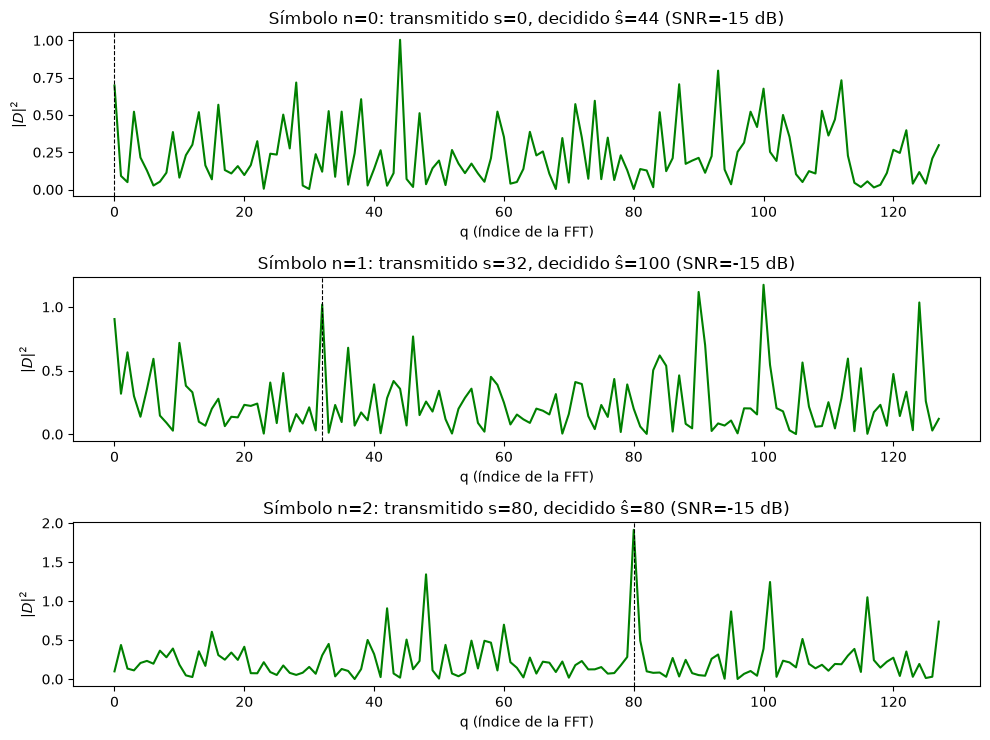

In [20]:
# Parámetros: probar distintos SNR para ver cuándo empieza a fallar la decisión
SF = 7
B = 125e3
symbols = np.array([0, 32, 80])
h_flat = np.array([1.0])  # Respuesta al impulso neutra
SNR_dB = -15

# Transmisión a través del canal ruidoso
c = modulator(symbols, SF, B)
z = noise_from_SNR(c, SNR_dB)
r = system(c, h_flat, z)

# Repetir los pasos de demodulator para ver la salida de la FFT antes de decidir
M: int = 2**SF
k = np.arange(M)
# Multiplicar cada símbolo recibido por el down-chirp
d = r.reshape(-1, M) * np.exp(-1j * 2 * np.pi * k**2 / M)
# FFT de cada símbolo
D = np.fft.fft(d, norm="ortho")
# Decisión: índice del máximo de |D|^2
symbols_rx = demodulator(r, SF)

plt.figure(figsize=(10, 2.5 * len(symbols)))
for n in range(len(symbols)):
    plt.subplot(len(symbols), 1, n + 1)
    plt.plot(np.abs(D[n]) ** 2, color="green")
    # Símbolo transmitido, para comparar con el pico
    plt.axvline(symbols[n], color="k", ls="--", lw=0.8)
    plt.title(
        f"Símbolo n={n}: transmitido s={symbols[n]}, decidido ŝ={symbols_rx[n]} (SNR={SNR_dB} dB)"
    )
    plt.xlabel("q (índice de la FFT)")
    plt.ylabel("$|D|^2$")
plt.tight_layout()
plt.show()

### Detección con ruido en un canal selectivo en frecuencia

Un canal no plano es selectivo en frecuencia. La respuesta al impulso del sistema usado para modelar un canal multicaminos es:

$$
h[n] = \sqrt{0.8}\,\delta[n] + \sqrt{0.2}\,\delta[n-1]
$$



### Performance de detección

Se analiza el BER vs SNR para el sistema simulado, el cual corresponde a la curva "Flat FSCM" de Fig. 1.

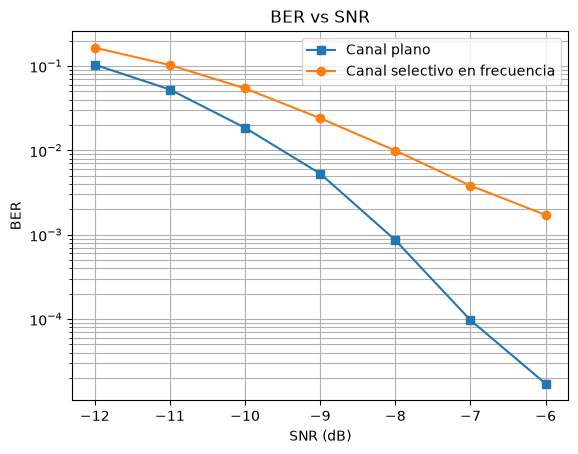

In [21]:
SF = 7
B = 125e3
h_flat = np.array([1.0])  # Canal plano (solo AWGN)
h_freq_sel = np.array([sqrt(0.8), sqrt(0.2)])
SNRs_dB = np.arange(-12.0, -5.0)  # -12 a -5 dB
num_symbols = 100  # Número de símbolos por simulación
simulations = 500  # Cantidad de simulaciones

# 300 simulaciones de 700 bits por punto con canal plano
bers_flat = [
    np.mean([simulation(SF, B, SNR_dB, h_flat) for _ in range(simulations)]) for SNR_dB in SNRs_dB
]
# 300 simulaciones de 700 bits por punto con canal selectivo en frecuencia
bers_freq_sel = [
    np.mean([simulation(SF, B, SNR_dB, h_freq_sel) for _ in range(simulations)])
    for SNR_dB in SNRs_dB
]

plt.semilogy(SNRs_dB, bers_flat, marker="s", label="Canal plano")
plt.semilogy(SNRs_dB, bers_freq_sel, marker="o", label="Canal selectivo en frecuencia")
plt.title("BER vs SNR")
plt.xlabel("SNR (dB)")
plt.ylabel("BER")
plt.grid(True, which="both")
plt.legend()
plt.show()

## Detección de una trama

En esta sección se analiza el problema de detectar una trama en un canal ruidoso del lado del receptor: decidir si llegó una trama y en qué muestra empieza (sincronización). La trama es un preámbulo de 8 *up-chirps* (símbolos 0) y 2.25 *down-chirps*, seguido del *payload*. Antes de la trama el receptor solo recibe ruido, y no sabe cuándo empieza.

Se plantean tres métodos:

1. **Correlación con el preámbulo completo** (tiempo): filtro adaptado con los 8 *up-chirps*, integración coherente.
2. **Búsqueda de 8 picos** (tiempo): correlación móvil con un solo *up-chirp*, sumando la energía de 8 picos separados un símbolo. Integración no coherente.
3. **Demodulación del preámbulo** (frecuencia): se demodula cada ventana y se cuentan las decididas como símbolo 0.

Para cada método se presenta el estadístico y su umbral de Neyman-Pearson, la validación en un canal ideal y la performance en un canal selectivo en frecuencia. Al final se comparan los tres métodos: detección del inicio, curva ROC y *Frame Error Rate* (FER).

In [22]:
def preamble(SF: int, B: float, n_upchirps: int = 8, n_downchirps: float = 2.25) -> np.ndarray:
    """Genera el preámbulo de una trama LoRa.

    El preámbulo se compone de `n_upchirps` up-chirps (símbolos 0) seguidos de `n_downchirps`
    down-chirps, que marcan el fin del preámbulo.

    Args:
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        n_upchirps (int): Cantidad de up-chirps.
        n_downchirps (float): Cantidad de down-chirps. Puede ser fraccionaria.

    Returns:
        np.ndarray: Preámbulo modulado (complejo) en el dominio del tiempo.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Up-chirps: símbolos 0 modulados
    upchirps = modulator(np.zeros(n_upchirps, dtype=int), SF, B)

    # Down-chirps: conjugado de un up-chirp (frecuencia instantánea decreciente)
    # Se generan los down-chirps completos necesarios y se recorta la fracción sobrante
    n_full = int(np.ceil(n_downchirps))
    downchirps = np.conj(modulator(np.zeros(n_full, dtype=int), SF, B))[: int(n_downchirps * M)]

    return np.concatenate([upchirps, downchirps])


def transmit_frame(
    symbols: np.ndarray, gap: int, SF: int, B: float, SNR_dB: float, h: np.ndarray
) -> np.ndarray:
    """Simula la transmisión de una trama a través de un canal ruidoso.

    La trama es el preámbulo seguido de los símbolos del payload. Antes de la trama, el receptor
    escucha `gap` símbolos de solo ruido, por lo que no sabe en qué símbolo empieza la trama.

    Args:
        symbols (np.ndarray): Símbolos del payload.
        gap (int): Cantidad de símbolos de silencio antes de la trama.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        SNR_dB (float): Relación señal-ruido en decibelios, respecto de la potencia de la trama.
        h (np.ndarray): Respuesta al impulso del canal.

    Returns:
        np.ndarray: Señal recibida después del canal ruidoso.
    """

    # Chips por símbolo
    M: int = 2**SF

    frame = np.concatenate([preamble(SF, B), modulator(symbols, SF, B)])

    # Silencio antes de la trama: el transmisor no emite nada
    c = np.concatenate([np.zeros(gap * M), frame])

    # El SNR se define respecto de la potencia de la trama, no del silencio
    # np.resize repite la trama hasta el largo de c: misma potencia y misma forma que c
    z = noise_from_SNR(np.resize(frame, c.size), SNR_dB)

    return system(c, h, z)

In [23]:
# Tests
assert preamble(7, 125e3).size == 8 * 2**7 + 9 * 2**7 // 4

### Escenario y herramientas comunes

**Escenario de validación**: el receptor escucha 5 símbolos de solo ruido antes de la trama. La validación de cada método se hace en un canal ideal (plano, $h[n] = \delta[n]$, solo AWGN) a $-10$ dB. La performance se evalúa además en el canal selectivo en frecuencia de la sección de BER, $h[n] = \sqrt{0.8}\,\delta[n] + \sqrt{0.2}\,\delta[n-1]$.

**Umbral**: los tres métodos fijan el umbral con el criterio de Neyman-Pearson para la misma probabilidad de falsa alarma por símbolo, $P_{FA}$. Su valor no se elige a mano: sale de la tasa de falsas alarmas que tolera el receptor. Cada falsa alarma hace que el receptor intente demodular una trama que no existe: gasta energía y, mientras tanto, puede perder una trama real. El receptor evalúa $B / 2^{SF}$ símbolos por segundo ($\approx 977$ con $SF = 7$ y $B = 125$ kHz), así que para tolerar $R_{FA}$ falsas alarmas por segundo:

$$
P_{FA} = R_{FA}\, \frac{2^{SF}}{B}
$$

Se toma una falsa alarma por minuto, $R_{FA} = 1/60\ \text{s}^{-1}$, de donde $P_{FA} \approx 1.7 \cdot 10^{-5}$ por símbolo. Como referencia, $P_{FA} = 10^{-3}$ daría casi una falsa alarma por segundo. Se asume que el receptor conoce la potencia del ruido $\sigma^2$; en la práctica se estima mientras no hay señal.

**Inicio de la trama**: las posiciones anteriores al inicio ya se superponen con parte del preámbulo, así que el primer cruce del umbral suele llegar antes de tiempo. `detect_start` declara $H_1$ en el primer cruce y estima el inicio como el máximo del estadístico en el largo del preámbulo siguiente. En el escenario el silencio dura 5 símbolos, menos que esa búsqueda: una falsa alarma en el silencio queda "rescatada" por el preámbulo que llega después. Por eso las falsas alarmas se validan aparte, sobre una señal de solo ruido (ver la comparación de los métodos).

**Métricas**:

- **Inicio correcto**: fracción de tramas cuyo inicio se detecta en la posición exacta. Una detección temprana (falsa alarma), una tardía o la no detección (*miss*) cuentan como error.
- **Frame Error Rate (FER)**: el BER evalúa cada bit por separado, pero en un sistema que transmite tramas la unidad útil es la trama: si un solo bit del *payload* es incorrecto la trama se descarta (en la práctica lo detecta un CRC), y si no se detecta el preámbulo se pierde la trama entera. Mide el sistema completo, detección y demodulación juntas: no sirve para comparar los detectores entre sí (ver la sección de FER).

$$
FER = \frac{\text{tramas con error}}{\text{tramas enviadas}}
$$

Una trama tiene error si ocurre cualquiera de estos eventos:

- **Miss**: no se detecta el preámbulo.
- **Inicio incorrecto** (falsa alarma, detección temprana o tardía): el *payload* se demodula con ventanas que no corresponden a sus símbolos.
- **Error de demodulación**: el inicio es correcto, pero algún símbolo del *payload* se decide mal.

Una vez detectada la muestra de inicio $\hat{k}$, el receptor conoce la estructura del preámbulo, por lo que el *payload* empieza $8 + 2.25$ símbolos después: en la muestra $\hat{k} + 10.25 \cdot 2^{SF}$. Si el inicio es correcto y los $N$ símbolos del *payload* se deciden de forma independiente con probabilidad de error de símbolo $SER$:

$$
FER = 1 - P(\text{inicio correcto})\,(1 - SER)^N
$$

El FER crece con el largo de la trama: aunque el BER sea bajo, una trama larga tiene más oportunidades de tener algún error. Para separar el aporte de la detección del de la demodulación, se compara cada detector con una detección ideal en la que el receptor conoce el inicio de la trama.

Cada método se resume en una función `detect(r, SF, B, noise_power, P_FA)` que devuelve la muestra de inicio detectada, o `None`. `frame_rates` simula tramas con cualquiera de ellas y estima ambas métricas.

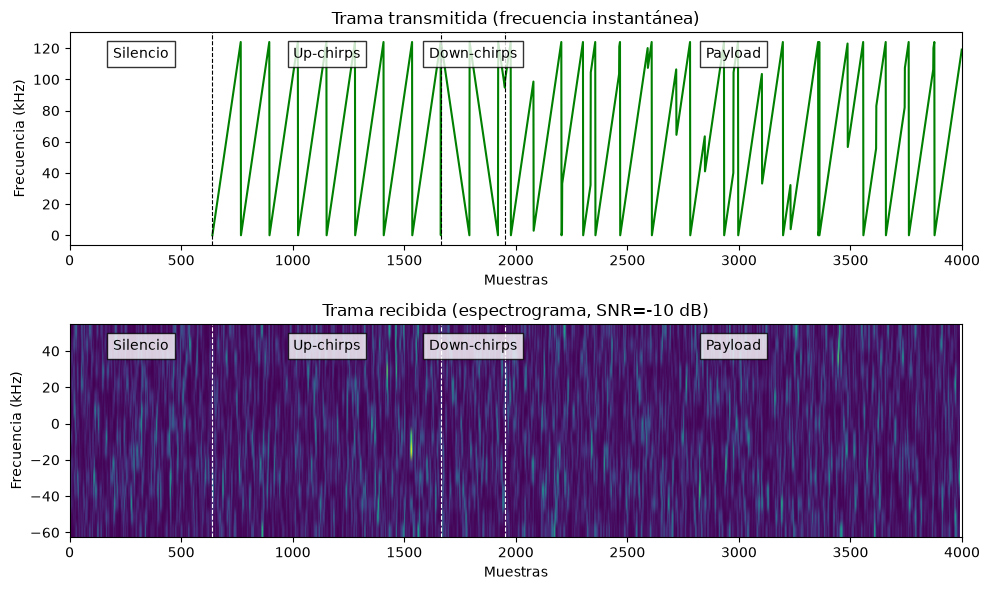

In [24]:
# Escenario para analizar las estrategias de detección
SF = 7
B = 125e3
M = 2**SF
SNR_dB = -10
gap = 5  # Símbolos de silencio antes de la trama: desconocido para el receptor
h_flat = np.array([1.0])  # Canal plano (solo AWGN)
symbols_tx = np.random.randint(0, M, size=16)  # Símbolos del payload

r = transmit_frame(symbols_tx, gap, SF, B, SNR_dB, h_flat)

# Potencia del ruido por muestra (sigma^2). Se asume que el receptor la conoce: en la práctica se
# estima mientras no hay señal
noise_power = power(preamble(SF, B)) / 10 ** (SNR_dB / 10)

# Estructura de la trama recibida: frecuencia instantánea sin ruido (arriba, con fines pedagógicos
# como en el análisis de la señal modulada) y espectrograma de la señal recibida (abajo)
# Con SNR negativo la trama no se distingue a simple vista en el espectrograma: hace falta un detector
k = np.arange(M)
f_up = k * B / M  # Up-chirp (símbolo 0): de 0 a B
f_down = ((M - k) % M) * B / M  # Down-chirp: de B a 0
f_payload = ((symbols_tx.reshape(-1, 1) + k) % M) * B / M  # Ec. 2 para cada símbolo del payload
f = np.concatenate(
    [
        np.full(gap * M, np.nan),  # Silencio: no hay señal
        np.tile(f_up, 8),
        np.tile(f_down, 3)[: 9 * M // 4],
        f_payload.ravel(),
    ]
)

# Límites entre partes de la trama y nombre de cada parte
bounds = [0, gap * M, (gap + 8) * M, (gap + 8) * M + 9 * M // 4, r.size]
names = ["Silencio", "Up-chirps", "Down-chirps", "Payload"]

plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(f / 1e3, color="green")
plt.title("Trama transmitida (frecuencia instantánea)")
plt.xlabel("Muestras")
plt.ylabel("Frecuencia (kHz)")
plt.subplot(2, 1, 2)
N = 16  # muestras por ventana de la FFT
plt.specgram(
    r,
    NFFT=N,
    noverlap=N - 1,
    Fs=B / 1e3,
    sides="twosided",
    scale="linear",
    xextent=(N / 2, r.size - N / 2),
)
plt.title(f"Trama recibida (espectrograma, SNR={SNR_dB} dB)")
plt.xlabel("Muestras")
plt.ylabel("Frecuencia (kHz)")
for ax in plt.gcf().axes:
    for x in bounds[1:-1]:
        # Blanco sobre el espectrograma (fondo oscuro), negro en el resto
        ax.axvline(x, color="w" if ax.images else "k", ls="--", lw=0.8)
    # Nombre de cada parte, centrado entre sus límites (x en muestras, y relativo al gráfico)
    for left, right, name in zip(bounds[:-1], bounds[1:], names):
        ax.text(
            (left + right) / 2,
            0.88,
            name,
            ha="center",
            transform=ax.get_xaxis_transform(),
            bbox=dict(facecolor="w", alpha=0.8),
        )
    ax.set_xlim(0, r.size)  # Mismo eje en ambos gráficos, incluyendo el silencio
plt.tight_layout()
plt.show()

In [25]:
def detect_start(statistic: np.ndarray, threshold: float, span: int = 8) -> int | None:
    """Detecta el inicio de la trama a partir de un estadístico de detección.

    Declara la trama presente (H1) en la primera posición donde el estadístico alcanza el umbral.
    Como las posiciones anteriores al inicio ya se superponen con parte del preámbulo, el primer
    cruce suele llegar antes de tiempo: el inicio es el máximo del estadístico en las `span`
    posiciones siguientes al cruce.

    Args:
        statistic (np.ndarray): Estadístico de detección de cada posición (muestra o ventana).
        threshold (float): Umbral de decisión.
        span (int): Posiciones donde se busca el máximo después del cruce: el largo del
            preámbulo, en ventanas (8) o en muestras (8 * 2^SF).

    Returns:
        int | None: Posición de inicio de la trama, o None si no se detecta.
    """

    # Posiciones que alcanzan el umbral
    above = np.flatnonzero(statistic >= threshold)
    if above.size == 0:
        return None  # No se detecta la trama: H0 en todas las posiciones

    # Máximo del estadístico a partir del primer cruce
    first = above[0]
    return int(first + np.argmax(statistic[first : first + span]))


def frame_error(
    r: np.ndarray, start: int | None, symbols_tx: np.ndarray, SF: int, B: float
) -> bool:
    """Determina si una trama se recibe con error.

    Demodula el payload a partir de la muestra de inicio detectada y lo compara con el transmitido.

    Args:
        r (np.ndarray): Señal recibida.
        start (int | None): Muestra de inicio de la trama detectada, o None si no se detectó.
        symbols_tx (np.ndarray): Símbolos del payload transmitido.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.

    Returns:
        bool: True si la trama tiene error.
    """

    # Miss: no se detectó el preámbulo, se pierde la trama
    if start is None:
        return True

    # Chips por símbolo
    M: int = 2**SF

    # El payload empieza después del preámbulo, cuya estructura conoce el receptor
    begin = start + preamble(SF, B).size
    payload = r[begin : begin + symbols_tx.size * M]

    # Detección tardía: el payload queda fuera de la señal recibida
    if payload.size < symbols_tx.size * M:
        return True

    # Basta un símbolo incorrecto para descartar la trama
    # Comparar símbolos equivale a comparar bits: el codificador es una biyección
    return not np.array_equal(demodulator(payload, SF), symbols_tx)


def frame_rates(
    detect: Callable[..., int | None],
    SNRs_dB: np.ndarray,
    h: np.ndarray,
    SF: int,
    B: float,
    P_FA: float,
    simulations: int,
    num_symbols: int = 16,
    gap: int = 5,
) -> tuple[np.ndarray, np.ndarray]:
    """Simula tramas con un detector y estima el inicio correcto y el FER para cada SNR.

    Args:
        detect (Callable): Detector. detect(r, SF, B, noise_power, P_FA) devuelve la muestra de
            inicio de la trama, o None si no la detecta.
        SNRs_dB (np.ndarray): SNR a simular, en decibelios.
        h (np.ndarray): Respuesta al impulso del canal.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        P_FA (float): Probabilidad de falsa alarma por símbolo.
        simulations (int): Tramas simuladas por SNR.
        num_symbols (int): Símbolos del payload por trama.
        gap (int): Símbolos de silencio antes de la trama.

    Returns:
        tuple[np.ndarray, np.ndarray]: Fracción de tramas con inicio correcto y FER, para cada SNR.
    """

    # Chips por símbolo
    M: int = 2**SF

    p_start, fer = np.zeros(len(SNRs_dB)), np.zeros(len(SNRs_dB))
    for i, SNR_dB in enumerate(SNRs_dB):
        # Potencia del ruido por muestra (sigma^2), que el receptor conoce
        noise_power = power(preamble(SF, B)) / 10 ** (SNR_dB / 10)
        for _ in range(simulations):
            symbols_tx = np.random.randint(0, M, size=num_symbols)
            r = transmit_frame(symbols_tx, gap, SF, B, SNR_dB, h)
            start = detect(r, SF, B, noise_power, P_FA)
            p_start[i] += start == gap * M
            fer[i] += frame_error(r, start, symbols_tx, SF, B)

    return p_start / simulations, fer / simulations


def detect_ideal(r: np.ndarray, SF: int, B: float, noise_power: float, P_FA: float) -> int:
    """Detección ideal: el receptor conoce el inicio de la trama (gap = 5 símbolos)."""
    return 5 * 2**SF

In [26]:
# Tests: sin ruido apreciable, la trama se recibe sin errores solo con el inicio correcto
symbols_test = np.random.randint(0, 2**7, size=8)
r_test = transmit_frame(symbols_test, 3, 7, 125e3, 100, np.array([1.0]))
noise_power_test = power(preamble(7, 125e3)) / 10 ** (100 / 10)
assert not frame_error(r_test, 3 * 2**7, symbols_test, 7, 125e3)
assert frame_error(r_test, 3 * 2**7 + 1, symbols_test, 7, 125e3)  # Una muestra de diferencia
assert frame_error(r_test, 2 * 2**7, symbols_test, 7, 125e3)
assert frame_error(r_test, None, symbols_test, 7, 125e3)
# Tests: con la detección ideal y sin ruido, todas las tramas son correctas
p_test, fer_test = frame_rates(detect_ideal, [100], np.array([1.0]), 7, 125e3, 1e-3, 3)
assert p_test[0] == 1 and fer_test[0] == 0

In [27]:
# Parámetros comunes a la validación y la performance de los tres métodos
R_FA = 1 / 60  # Tasa de falsas alarmas tolerable: una por minuto
P_FA = R_FA * 2**SF / B  # Probabilidad de falsa alarma por símbolo
h_freq_sel = np.array([sqrt(0.8), sqrt(0.2)])  # Canal selectivo de la sección de BER
SNRs_rates_dB = np.arange(-24.0, -3.0, 1.0)  # -24 a -4 dB
simulations = 300  # Tramas simuladas por SNR

### Detección en el tiempo: correlación móvil con un up-chirp

En el tiempo el receptor no necesita sincronía de símbolo: desliza una plantilla conocida sobre la señal recibida, muestra a muestra, y busca dónde se parece más. La muestra $k$ donde se decide $H_1$ es a la vez la detección y la sincronización: es donde empieza la trama.

Para cada muestra $k$ se plantea un test de hipótesis binario:

- $H_0$: el preámbulo no empieza en la muestra $k$. Se recibe solo ruido, u otra parte de la trama.
- $H_1$: el preámbulo empieza en la muestra $k$: $r_k = p + w$, donde $r_k$ son las muestras recibidas a partir de $k$, $p$ son los 8 *up-chirps* del preámbulo (conocidos) y $w$ es ruido gaussiano i.i.d.

Los dos métodos parten de la correlación móvil de la señal recibida con un solo *up-chirp* (símbolo 0):

$$
y[k] = \langle r_k, c|_{s=0} \rangle = \sum_{i=0}^{2^{SF}-1} r(kT + iT)\, c^*(iT)|_{s=0}
$$

Dentro del preámbulo, $|y[k]|^2$ es máxima cuando la plantilla queda alineada con un *up-chirp*, y nula con cualquier otro desplazamiento: un *up-chirp* desplazado en el tiempo es un *up-chirp* con un corrimiento de frecuencia, ortogonal al original.

Los picos aparecen cada $2^{SF}/2$ muestras y no cada $2^{SF}$. Con la fase de la Ec. 2, $2\pi k^2 / 2^{SF}$ para el símbolo 0, la frecuencia instantánea real (la derivada de la fase) barre de 0 a $2B$ y, muestreada a $B$, se repliega: cada *up-chirp* son dos copias de un *chirp* de $2^{SF}/2$ muestras, y el preámbulo produce 16 picos.

In [28]:
def upchirp_correlation(r: np.ndarray, SF: int, B: float) -> np.ndarray:
    """Correlación móvil de la señal recibida con un up-chirp (símbolo 0).

    Calcula y[k] = <r_k, c|_{s=0}> para cada muestra k, donde r_k son las 2^SF muestras recibidas a
    partir de k.

    Args:
        r (np.ndarray): Señal recibida.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.

    Returns:
        np.ndarray: Correlación y[k] para cada muestra k donde entra el up-chirp completo.
    """

    upchirp = modulator(np.zeros(1, dtype=int), SF, B)

    # np.correlate conjuga el segundo argumento: y[k] = sum_i r[k + i] * conj(upchirp[i])
    return np.correlate(r, upchirp, mode="valid")

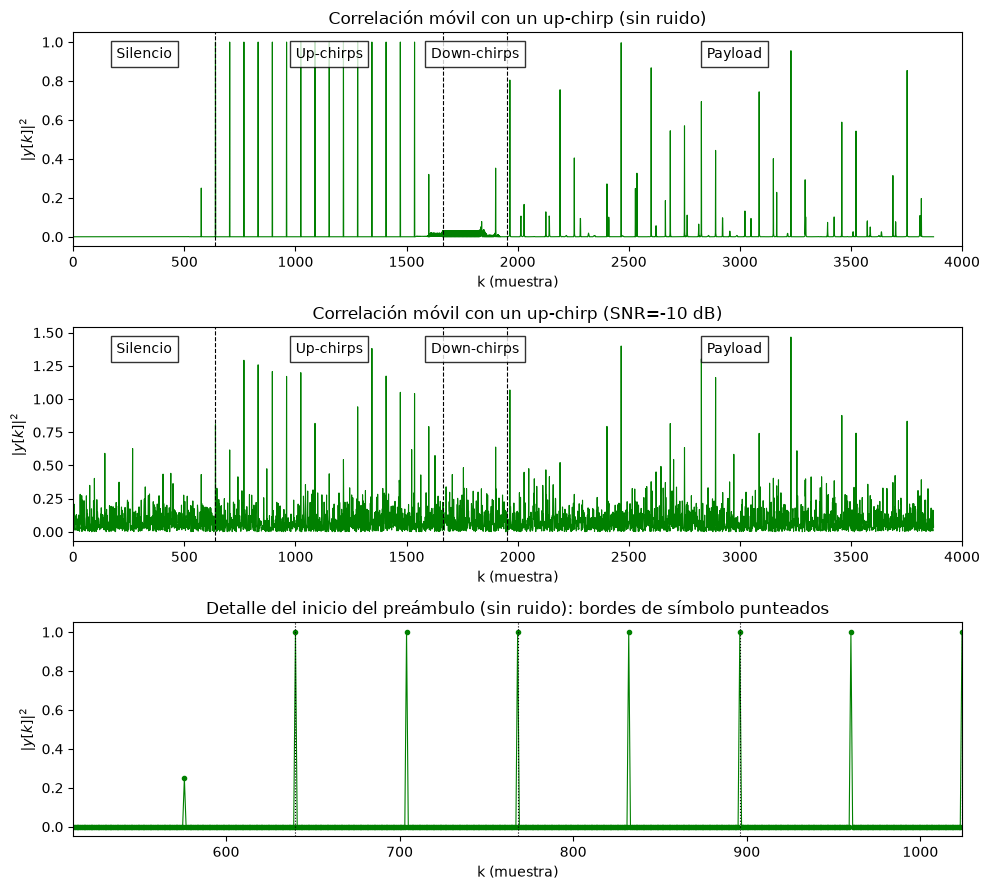

In [29]:
# Correlación móvil con un up-chirp sobre la trama del escenario
r_clean = transmit_frame(symbols_tx, gap, SF, B, 100, h_flat)  # SNR de 100 dB: sin ruido apreciable
y_clean = upchirp_correlation(r_clean, SF, B)
y = upchirp_correlation(r, SF, B)

plt.figure(figsize=(10, 9))
plt.subplot(3, 1, 1)
plt.plot(np.abs(y_clean) ** 2, color="green", lw=0.8)
plt.title("Correlación móvil con un up-chirp (sin ruido)")
plt.subplot(3, 1, 2)
plt.plot(np.abs(y) ** 2, color="green", lw=0.8)
plt.title(f"Correlación móvil con un up-chirp (SNR={SNR_dB} dB)")
for ax in plt.gcf().axes:
    for x in bounds[1:-1]:
        ax.axvline(x, color="k", ls="--", lw=0.8)
    # Nombre de cada parte, centrado entre sus límites (x en muestras, y relativo al gráfico)
    for left, right, name in zip(bounds[:-1], bounds[1:], names):
        ax.text(
            (left + right) / 2,
            0.88,
            name,
            ha="center",
            transform=ax.get_xaxis_transform(),
            bbox=dict(facecolor="w", alpha=0.8),
        )
    ax.set_xlim(0, r.size)
    ax.set_xlabel("k (muestra)")
    ax.set_ylabel("$|y[k]|^2$")

# Detalle sin ruido del inicio del preámbulo: un pico en cada borde de símbolo y otro en el medio
plt.subplot(3, 1, 3)
plt.plot(np.abs(y_clean) ** 2, marker=".", color="green", lw=0.8)
for n in range(4):
    plt.axvline((gap + n) * M, color="k", ls=":", lw=0.8)
plt.xlim((gap - 1) * M, (gap + 3) * M)
plt.title("Detalle del inicio del preámbulo (sin ruido): bordes de símbolo punteados")
plt.xlabel("k (muestra)")
plt.ylabel("$|y[k]|^2$")
plt.tight_layout()
plt.show()

**Observaciones**:
- Sin ruido se ve la estructura de la trama: picos de altura 1 cada $2^{SF}/2$ muestras durante los *up-chirps*, nada en el silencio ni en los *down-chirps*, y picos aislados en el *payload* (donde un símbolo, o una mezcla de dos símbolos consecutivos, se parece a un *up-chirp*).
- Con ruido los picos del preámbulo siguen sobresaliendo, pero el ruido también produce picos: decidir con uno solo daría muchas falsas alarmas. Los dos métodos en el tiempo combinan los 8 picos que deja el preámbulo, separados un símbolo: uno en forma coherente y otro no coherente.

### Detección en el tiempo: correlación con el preámbulo completo

La plantilla es el preámbulo completo de 8 *up-chirps*, $p$. Es el problema de detectar una señal conocida en ruido gaussiano: el test de razón de verosimilitud se reduce a correlar la señal recibida con la señal conocida (filtro adaptado) y comparar con un umbral. Como la fase de la señal recibida es desconocida, se compara el módulo al cuadrado:

$$
T[k] = \left| \langle r_k, p \rangle \right|^2 = \left| \sum_{n=0}^{7} y[k + n\,2^{SF}] \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta
$$

Como $p$ son *up-chirps* repetidos, correlar con $p$ es sumar los 8 picos de $y[k]$ separados un símbolo. La suma es coherente (antes del módulo): las amplitudes de la señal se suman en fase (potencia $\times 64$) mientras que las potencias del ruido se suman ($\times 8$), una ganancia de $10\log_{10} 8 \approx 9$ dB respecto de un solo pico. A cambio, necesita que la fase de la señal se mantenga durante los 8 símbolos: un corrimiento de frecuencia entre transmisor y receptor rota los picos y la suma deja de ser coherente.

**Umbral (Neyman-Pearson)**: no se conocen las probabilidades *a priori* de $H_0$ y $H_1$, por lo que se fija la probabilidad de falsa alarma $P_{FA}$ tolerable. Cada *chirp* tiene energía 1, así que bajo $H_0$ cada $y[k + n\,2^{SF}]$ es gaussiano complejo de varianza $\sigma^2$ (potencia del ruido por muestra), la suma de 8 tiene varianza $8\sigma^2$ y $T[k]$ tiene distribución exponencial de media $8\sigma^2$:

$$
P_{FA} = P(T[k] > \eta \mid H_0) = e^{-\eta / 8\sigma^2} \quad\Rightarrow\quad \eta = -8\sigma^2 \ln P_{FA}
$$

Se asume que el receptor conoce $\sigma^2$; en la práctica se estima mientras no hay señal. $P_{FA}$ es por muestra: el test se repite en las $2^{SF}$ muestras de cada símbolo. Para tener la misma tasa de falsas alarmas que un test por símbolo con $P_{FA}$, se usa $P_{FA} / 2^{SF}$ en cada muestra.

**Inicio de la trama**: alrededor del inicio, $T[k]$ es un peine. Cada $2^{SF}/2$ muestras la plantilla vuelve a alinearse con parte del preámbulo: con $j$ medios *chirps* fuera, $T \approx 64\,(1 - j/16)^2$. El primer cruce del umbral suele ser uno de estos picos laterales, antes del inicio, así que el inicio se estima como el máximo de $T[k]$ en los 8 símbolos ($8 \cdot 2^{SF}$ muestras) siguientes al primer cruce.

Los *down-chirps* del preámbulo no intervienen en la detección.

In [30]:
def preamble_correlation(r: np.ndarray, SF: int, B: float, n_upchirps: int = 8) -> np.ndarray:
    """Estadístico de la correlación con el preámbulo completo.

    Calcula T[k] = |<r_k, p>|^2 para cada muestra k (filtro adaptado), donde p son los
    `n_upchirps` up-chirps del preámbulo y r_k es la señal recibida a partir de la muestra k.

    Args:
        r (np.ndarray): Señal recibida.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        n_upchirps (int): Cantidad de up-chirps del preámbulo.

    Returns:
        np.ndarray: Estadístico T[k] para cada muestra k donde entra el preámbulo completo.
    """

    p = modulator(np.zeros(n_upchirps, dtype=int), SF, B)

    # Equivale a sumar los picos y[k + n M] de upchirp_correlation antes del módulo (coherente)
    return np.abs(np.correlate(r, p, mode="valid")) ** 2


def time_threshold(noise_power: float, P_FA: float, n_upchirps: int = 8) -> float:
    """Umbral de Neyman-Pearson para el estadístico de `preamble_correlation`.

    Bajo H0, T[k] tiene distribución exponencial de media n_upchirps * noise_power.

    Args:
        noise_power (float): Potencia del ruido por muestra (sigma^2).
        P_FA (float): Probabilidad de falsa alarma por muestra.
        n_upchirps (int): Cantidad de up-chirps del preámbulo.

    Returns:
        float: Umbral eta tal que P(T[k] > eta | H0) = P_FA.
    """

    # ||p||^2 = n_upchirps: cada chirp tiene energía 1
    return -n_upchirps * noise_power * np.log(P_FA)


def detect_full(r: np.ndarray, SF: int, B: float, noise_power: float, P_FA: float) -> int | None:
    """Detecta la muestra de inicio de la trama con la correlación con el preámbulo completo.

    Args:
        r (np.ndarray): Señal recibida.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        noise_power (float): Potencia del ruido por muestra (sigma^2).
        P_FA (float): Probabilidad de falsa alarma por símbolo.

    Returns:
        int | None: Muestra de inicio de la trama, o None si no se detecta.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Se prueban M muestras por símbolo: P_FA / M en cada una
    eta = time_threshold(noise_power, P_FA / M)

    # El máximo se busca en el largo de los up-chirps del preámbulo
    return detect_start(preamble_correlation(r, SF, B), eta, 8 * M)

#### Validación en canal ideal

Sin ruido apreciable, el inicio detectado debe ser exactamente el real (tests). Luego se aplica el método al escenario de validación: canal plano a $-10$ dB.

In [31]:
# Tests: sin ruido apreciable, el inicio detectado es la muestra real
T_test = preamble_correlation(r_test, 7, 125e3)
assert detect_start(T_test, time_threshold(noise_power_test, 1e-3), 8 * 2**7) == 3 * 2**7
assert detect_full(r_test, 7, 125e3, noise_power_test, 1e-3) == 3 * 2**7

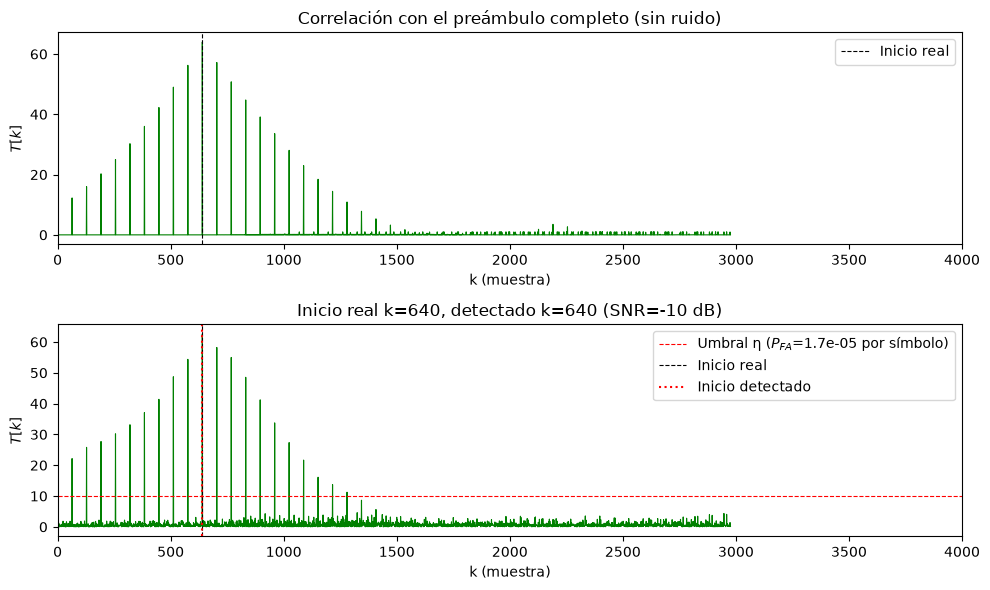

In [32]:
# Correlación con el preámbulo completo sobre el escenario
eta = time_threshold(noise_power, P_FA / M)  # Se prueban M muestras por símbolo
T = preamble_correlation(r, SF, B)
T_clean = preamble_correlation(r_clean, SF, B)
start = detect_start(T, eta, 8 * M)

plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(T_clean, color="green", lw=0.8)
plt.axvline(gap * M, color="k", ls="--", lw=0.8, label="Inicio real")
plt.title("Correlación con el preámbulo completo (sin ruido)")
plt.subplot(2, 1, 2)
plt.plot(T, color="green", lw=0.8)
plt.axhline(eta, color="r", ls="--", lw=0.8, label=f"Umbral η ($P_{{FA}}$={P_FA:.1e} por símbolo)")
plt.axvline(gap * M, color="k", ls="--", lw=0.8, label="Inicio real")
if start is not None:
    plt.axvline(start, color="r", ls=":", label="Inicio detectado")
plt.title(f"Inicio real k={gap * M}, detectado k={start} (SNR={SNR_dB} dB)")
for ax in plt.gcf().axes:
    ax.set_xlabel("k (muestra)")
    ax.set_ylabel("$T[k]$")
    ax.set_xlim(0, r.size)
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

#### Performance en canal selectivo en frecuencia

Se estima la probabilidad de detectar el inicio correcto en función del SNR, en el canal selectivo y en el plano como referencia. El FER se guarda para la comparación final.

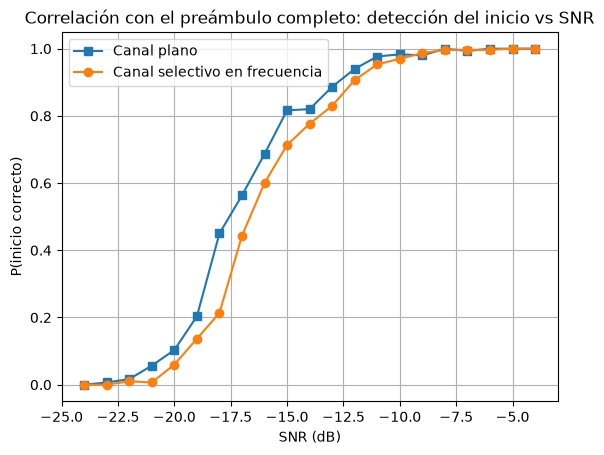

In [33]:
# Inicio correcto y FER en el canal plano y en el selectivo en frecuencia
p_full_flat, fer_full_flat = frame_rates(
    detect_full, SNRs_rates_dB, h_flat, SF, B, P_FA, simulations
)
p_full_sel, fer_full_sel = frame_rates(
    detect_full, SNRs_rates_dB, h_freq_sel, SF, B, P_FA, simulations
)

plt.plot(SNRs_rates_dB, p_full_flat, marker="s", label="Canal plano")
plt.plot(SNRs_rates_dB, p_full_sel, marker="o", label="Canal selectivo en frecuencia")
plt.title("Correlación con el preámbulo completo: detección del inicio vs SNR")
plt.xlabel("SNR (dB)")
plt.ylabel("P(inicio correcto)")
plt.grid(True)
plt.legend()
plt.show()

**Observaciones**:
- En el canal plano el inicio se encuentra en la mitad de las tramas cerca de $-17.5$ dB, y en todas desde $-9$ dB.
- El canal selectivo cuesta $\approx 1$ dB. La plantilla solo captura el camino principal, que lleva el 80 % de la energía ($10\log_{10} 0.8 \approx -1$ dB). El eco produce otro pico una muestra después, más débil, que no confunde la localización.

### Detección en el tiempo: búsqueda de 8 picos

En lugar de un pico de la correlación con el preámbulo completo, se buscan los 8 picos que deja el preámbulo en la correlación móvil con un solo *up-chirp*: 8 picos seguidos, separados un tiempo de símbolo ($2^{SF}$ muestras). El estadístico suma la energía de los 8 picos candidatos a partir de la muestra $k$:

$$
S[k] = \sum_{n=0}^{7} \left| y[k + n\,2^{SF}] \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta_S
$$

La diferencia con $T[k]$ es dónde se toma el módulo. $T[k]$ suma los picos y después toma el módulo (integración coherente); $S[k]$ toma el módulo de cada pico y después suma (integración no coherente). Al sumar energías se descarta la fase de cada pico: el método tolera que la fase cambie entre símbolos, pero el ruido de cada pico suma su energía en lugar de promediarse con el de los demás, por lo que se espera que necesite más SNR que $T[k]$.

Los picos intermedios, a $2^{SF}/2$ muestras, no se usan. Con picos separados un símbolo las 8 correlaciones usan muestras disjuntas, y bajo $H_0$ son independientes.

**Umbral (Neyman-Pearson)**: bajo $H_0$ cada $y[k + n\,2^{SF}]$ es gaussiano complejo de varianza $\sigma^2$, así que $|y|^2$ es exponencial de media $\sigma^2$. Los 8 son independientes, por lo que $S[k]$ tiene distribución Gamma de orden 8 (Erlang) y escala $\sigma^2$, con cola en forma cerrada:

$$
P_{FA} = P(S[k] > \eta_S \mid H_0) = e^{-\eta_S/\sigma^2} \sum_{i=0}^{7} \frac{(\eta_S/\sigma^2)^i}{i!}
$$

$\eta_S$ no se puede despejar, pero la cola es decreciente en $\eta_S$: se busca por bisección. Igual que en $T[k]$, se usa $P_{FA} / 2^{SF}$ por muestra.

**Inicio de la trama**: $S[k]$ también es un peine alrededor del inicio. Con $j$ medios *chirps* fuera del preámbulo, los 8 picos candidatos caen en picos intermedios, o fuera del preámbulo: $S \approx 8 - j/2$. Los picos laterales de $S[k]$ son más altos, relativos al principal, que los de $T[k]$, y el inicio se estima de la misma forma: el máximo en los 8 símbolos siguientes al primer cruce.

In [34]:
def peaks_statistic(r: np.ndarray, SF: int, B: float, n_upchirps: int = 8) -> np.ndarray:
    """Estadístico de la búsqueda de picos: energía de `n_upchirps` picos separados un símbolo.

    Calcula S[k] = sum_n |y[k + n 2^SF]|^2 a partir de la correlación móvil con un up-chirp.

    Args:
        r (np.ndarray): Señal recibida.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        n_upchirps (int): Cantidad de up-chirps del preámbulo.

    Returns:
        np.ndarray: Estadístico S[k] para cada muestra k donde entran los `n_upchirps` picos.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Energía de cada pico: el módulo se toma antes de sumar (no coherente)
    y2 = np.abs(upchirp_correlation(r, SF, B)) ** 2

    # Posiciones k donde entran los n_upchirps picos: mismo largo que preamble_correlation
    n_valid = y2.size - (n_upchirps - 1) * M

    # Suma de los picos y[k + n M], desplazando el arreglo un símbolo por cada pico
    return sum(y2[n * M : n * M + n_valid] for n in range(n_upchirps))


def peaks_threshold(noise_power: float, P_FA: float, n_upchirps: int = 8) -> float:
    """Umbral de Neyman-Pearson para el estadístico de `peaks_statistic`.

    Bajo H0, S[k] tiene distribución Gamma de orden n_upchirps y escala noise_power. Su cola no
    se puede invertir en forma cerrada: el umbral se busca por bisección.

    Args:
        noise_power (float): Potencia del ruido por muestra (sigma^2).
        P_FA (float): Probabilidad de falsa alarma por muestra.
        n_upchirps (int): Cantidad de up-chirps del preámbulo.

    Returns:
        float: Umbral eta_S tal que P(S[k] > eta_S | H0) = P_FA.
    """

    def tail(x: float) -> float:
        # P(S[k] > x sigma^2 | H0): cola de la Gamma de orden entero (Erlang)
        return np.exp(-x) * sum(x**i / factorial(i) for i in range(n_upchirps))

    # Intervalo [lo, hi] que contiene la solución: se duplica hi hasta que la cola baje de P_FA
    lo, hi = 0.0, 1.0
    while tail(hi) > P_FA:
        lo, hi = hi, 2 * hi

    # Bisección: la cola es decreciente en x
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if tail(mid) > P_FA else (lo, mid)

    return hi * noise_power


def detect_peaks(r: np.ndarray, SF: int, B: float, noise_power: float, P_FA: float) -> int | None:
    """Detecta la muestra de inicio de la trama con la búsqueda de 8 picos.

    Args:
        r (np.ndarray): Señal recibida.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        noise_power (float): Potencia del ruido por muestra (sigma^2).
        P_FA (float): Probabilidad de falsa alarma por símbolo.

    Returns:
        int | None: Muestra de inicio de la trama, o None si no se detecta.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Se prueban M muestras por símbolo: P_FA / M en cada una
    eta_S = peaks_threshold(noise_power, P_FA / M)

    # El máximo se busca en el largo de los up-chirps del preámbulo
    return detect_start(peaks_statistic(r, SF, B), eta_S, 8 * M)

#### Validación en canal ideal

Sin ruido apreciable, el inicio detectado debe ser exactamente el real (tests). Luego se aplica el método al escenario de validación: canal plano a $-10$ dB.

In [35]:
# Tests: con un solo pico, S[k] es exponencial y el umbral coincide con el de T[k] para n = 1
assert np.isclose(peaks_threshold(2.0, 1e-3, 1), time_threshold(2.0, 1e-3, 1))
# Tests: el umbral cumple la P_FA pedida (cola de la Erlang de orden 8)
x = peaks_threshold(1.0, 1e-3) / 1.0
assert np.isclose(np.exp(-x) * sum(x**i / factorial(i) for i in range(8)), 1e-3)
# Tests: sin ruido apreciable, el inicio detectado es la muestra real
S_test = peaks_statistic(r_test, 7, 125e3)
assert S_test.size == T_test.size
assert detect_start(S_test, peaks_threshold(noise_power_test, 1e-3), 8 * 2**7) == 3 * 2**7
assert detect_peaks(r_test, 7, 125e3, noise_power_test, 1e-3) == 3 * 2**7

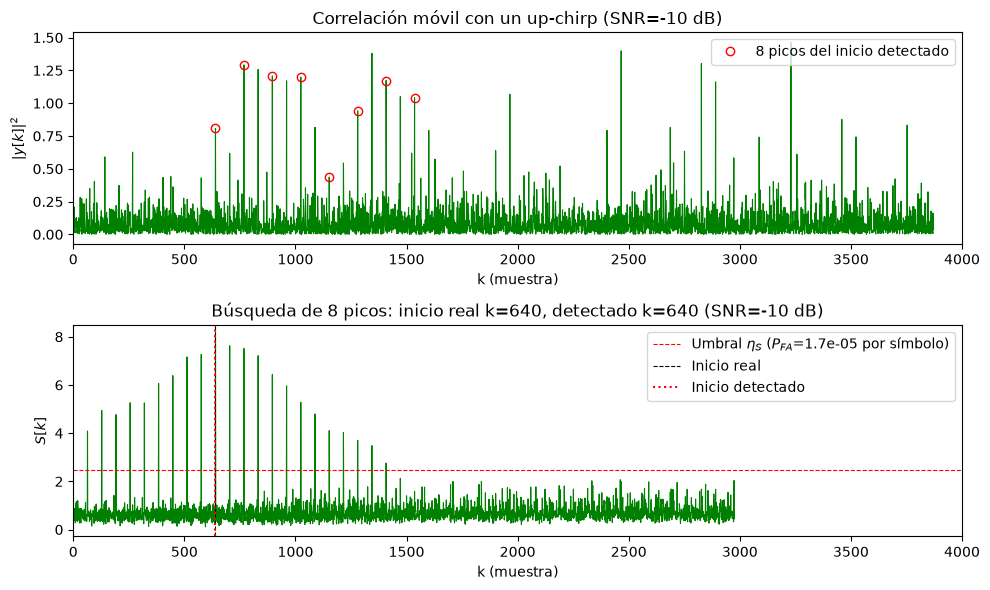

In [36]:
# Búsqueda de 8 picos sobre el escenario
eta_S = peaks_threshold(noise_power, P_FA / M)  # Se prueban M muestras por símbolo
S = peaks_statistic(r, SF, B)
start = detect_start(S, eta_S, 8 * M)

plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(np.abs(y) ** 2, color="green", lw=0.8)
if start is not None:
    # Los 8 picos que suma S[k] en el inicio detectado
    peaks = start + np.arange(8) * M
    plt.plot(
        peaks,
        np.abs(y[peaks]) ** 2,
        "o",
        mfc="none",
        color="r",
        label="8 picos del inicio detectado",
    )
    plt.legend(loc="upper right")
plt.title(f"Correlación móvil con un up-chirp (SNR={SNR_dB} dB)")
plt.ylabel("$|y[k]|^2$")
plt.subplot(2, 1, 2)
plt.plot(S, color="green", lw=0.8)
plt.axhline(
    eta_S, color="r", ls="--", lw=0.8, label=f"Umbral $η_S$ ($P_{{FA}}$={P_FA:.1e} por símbolo)"
)
plt.axvline(gap * M, color="k", ls="--", lw=0.8, label="Inicio real")
if start is not None:
    plt.axvline(start, color="r", ls=":", label="Inicio detectado")
plt.title(f"Búsqueda de 8 picos: inicio real k={gap * M}, detectado k={start} (SNR={SNR_dB} dB)")
plt.ylabel("$S[k]$")
plt.legend(loc="upper right")
for ax in plt.gcf().axes:
    ax.set_xlabel("k (muestra)")
    ax.set_xlim(0, r.size)
plt.tight_layout()
plt.show()

#### Performance en canal selectivo en frecuencia

Se estima la probabilidad de detectar el inicio correcto en función del SNR, en el canal selectivo y en el plano como referencia. El FER se guarda para la comparación final.

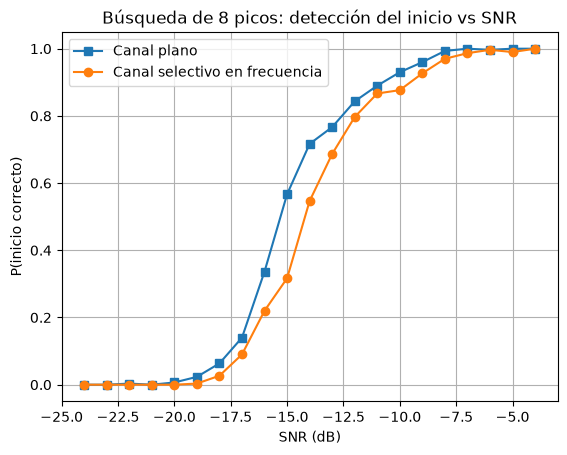

In [37]:
# Inicio correcto y FER en el canal plano y en el selectivo en frecuencia
p_peaks_flat, fer_peaks_flat = frame_rates(
    detect_peaks, SNRs_rates_dB, h_flat, SF, B, P_FA, simulations
)
p_peaks_sel, fer_peaks_sel = frame_rates(
    detect_peaks, SNRs_rates_dB, h_freq_sel, SF, B, P_FA, simulations
)

plt.plot(SNRs_rates_dB, p_peaks_flat, marker="s", label="Canal plano")
plt.plot(SNRs_rates_dB, p_peaks_sel, marker="o", label="Canal selectivo en frecuencia")
plt.title("Búsqueda de 8 picos: detección del inicio vs SNR")
plt.xlabel("SNR (dB)")
plt.ylabel("P(inicio correcto)")
plt.grid(True)
plt.legend()
plt.show()

**Observaciones**:
- En el canal plano el inicio se encuentra en la mitad de las tramas cerca de $-15$ dB, unos 2 dB peor que la correlación con el preámbulo completo. Es la pérdida de la integración no coherente: el ruido de cada pico suma su energía.
- La localización es más débil: con medio símbolo de error los 8 picos candidatos caen sobre los picos intermedios y $S \approx 7.25$, contra 8 en el inicio. Cuando la detección falla cerca del inicio, suele ser por $2^{SF}/2$ muestras (se puede ver repitiendo el escenario de validación).
- El canal selectivo cuesta $\approx 1$ dB, por la misma razón que en la correlación con el preámbulo completo.

### Detección en frecuencia: demodulación del preámbulo

A diferencia de la detección en el tiempo, se asume sincronía de símbolo: el receptor divide la señal recibida en ventanas de $2^{SF}$ muestras alineadas con los bordes de los símbolos, y lo que no conoce es en qué ventana $m$ empieza la trama. Las hipótesis son las mismas que en el tiempo, por ventana en lugar de por muestra.

La estrategia en frecuencia reutiliza el demodulador (Ec. 16): cada ventana se multiplica por el *down-chirp* y se calcula su FFT. Durante el preámbulo cada ventana es un *up-chirp* de símbolo 0, por lo que el pico de la FFT aparece en el bin $q = 0$.

Mirar solo el bin 0 no aporta nada nuevo: por definición de la DFT, $D_n[0]$ es la suma de las muestras de la ventana multiplicadas por el *down-chirp*, es decir, la correlación móvil $y[k]$ de la detección en el tiempo evaluada en el borde de la ventana, $k = n\,2^{SF}$. La diferencia está en usar los $2^{SF}$ bins: el bin 0 se compara con los demás en vez de con un umbral absoluto. El estadístico es la cantidad de ventanas, entre 8 consecutivas, en las que el demodulador decide el símbolo $\hat{s}[n] = 0$, como en un *up-chirp* del preámbulo:

$$
V[m] = \sum_{n=m}^{m+7} \mathbb{1}\{\hat{s}[n] = 0\} \;\underset{H_0}{\overset{H_1}{\gtrless}}\; K
$$

Un umbral $K < 8$ tolera ventanas del preámbulo mal decididas por el ruido. El inicio se estima igual que en el tiempo: el máximo de $V[m]$ después del primer cruce.

**Umbral (Neyman-Pearson)**: como en el tiempo, se fija la $P_{FA}$ tolerable y se busca el umbral que la respeta. Bajo $H_0$ cada ventana es ruido blanco gaussiano, y su FFT (unitaria) también lo es: el máximo cae en cualquiera de los $2^{SF}$ bins con igual probabilidad, así que cada ventana se decide como símbolo 0 con probabilidad $p_0 = 2^{-SF}$. El ruido de ventanas distintas es independiente, por lo que $V[m]$ tiene distribución binomial $\mathcal{B}(8, p_0)$:

$$
P_{FA}(K) = P(V[m] \geq K \mid H_0) = \sum_{k=K}^{8} \binom{8}{k} p_0^k (1 - p_0)^{8-k}
$$

$V[m]$ es discreto, así que en general ningún $K$ da exactamente la $P_{FA}$ pedida. Bajar el umbral sube la $P_D$, por lo que Neyman-Pearson elige el menor $K$ con $P_{FA}(K) \leq P_{FA}$ (alcanzar la $P_{FA}$ exacta requiere aleatorizar la decisión entre $K - 1$ y $K$, como se ve en la curva ROC). Hay un test por ventana, así que $P_{FA}$ se usa sin dividir: la misma tasa de falsas alarmas por símbolo que en el tiempo. Para $SF = 7$ y $P_{FA} \approx 1.7 \cdot 10^{-5}$, $P_{FA}(3) \approx 2.6 \cdot 10^{-5}$ no la respeta y $P_{FA}(4) \approx 2.5 \cdot 10^{-7}$ sí, así que $K = 4$. Por ser discreto, el umbral opera con una $P_{FA}$ unas 70 veces menor que la tolerada. Un umbral más alto, como $K = 6$ ($P_{FA} \approx 6 \cdot 10^{-12}$), respeta la restricción con mucho margen pero pierde detecciones.

- **Ventaja**: el umbral no depende de $\sigma^2$, ya que la decisión de cada ventana es relativa entre bins: la distribución de $V[m]$ bajo $H_0$ solo depende de $SF$. No hace falta conocer ni estimar la potencia del ruido.
- **Desventaja**: cada ventana toma una decisión dura con la energía de un solo símbolo, y se pierde la ganancia de 9 dB de la suma coherente. Se espera que necesite más SNR que la detección en el tiempo.
- **Empates**: con probabilidad $2^{-SF}$ la ventana de ruido justo antes del preámbulo también se decide como símbolo 0, y $V[m]$ empata en 8 con el inicio real. `detect_start` elige la primera ventana del empate, un error de $\approx 0.8\%$ que no baja con el SNR. En el tiempo no hay empates, porque $T[k]$ es continuo.

In [38]:
def preamble_zero_count(r: np.ndarray, SF: int, n_upchirps: int = 8) -> np.ndarray:
    """Estadístico de detección en frecuencia: ventanas consecutivas decididas como símbolo 0.

    Demodula cada ventana (down-chirp y FFT, Ec. 16) y cuenta cuántas de las `n_upchirps`
    ventanas a partir de m se decidieron como símbolo 0.

    Args:
        r (np.ndarray): Señal recibida.
        SF (int): Spreading factor.
        n_upchirps (int): Cantidad de up-chirps del preámbulo.

    Returns:
        np.ndarray: Estadístico V[m] (ventanas con símbolo 0) para cada ventana m donde entra el
        preámbulo completo.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Demodular cada ventana de M muestras (sincronía de símbolo). Se descarta el resto
    symbols_rx = demodulator(r[: r.size // M * M], SF)

    # 1 si el pico de la FFT de la ventana está en el bin 0, como en un up-chirp del preámbulo
    is_zero = (symbols_rx == 0).astype(int)

    # Cantidad de ventanas con símbolo 0 en las n_upchirps ventanas a partir de m
    return np.convolve(is_zero, np.ones(n_upchirps, dtype=int), mode="valid")


def zero_count_false_alarm(K: int, SF: int, n_upchirps: int = 8) -> float:
    """Probabilidad de falsa alarma del estadístico de `preamble_zero_count` con umbral K.

    Bajo H0, cada ventana se decide como símbolo 0 con probabilidad 2^-SF, así que V[m] tiene
    distribución binomial B(n_upchirps, 2^-SF).

    Args:
        K (int): Umbral de decisión.
        SF (int): Spreading factor.
        n_upchirps (int): Cantidad de up-chirps del preámbulo.

    Returns:
        float: P(V[m] >= K | H0).
    """

    # Probabilidad de decidir símbolo 0 en una ventana de solo ruido: el pico cae en cualquier bin
    p0 = 2.0**-SF

    # Cola de la binomial: suma de P(V[m] = k | H0) para k = K, ..., n_upchirps
    return sum(
        comb(n_upchirps, k) * p0**k * (1 - p0) ** (n_upchirps - k) for k in range(K, n_upchirps + 1)
    )


def freq_threshold(P_FA: float, SF: int, n_upchirps: int = 8) -> int:
    """Umbral de Neyman-Pearson para el estadístico de `preamble_zero_count`.

    Como V[m] es discreto, se elige el menor umbral (mayor P_D) cuya probabilidad de falsa alarma
    no supera P_FA.

    Args:
        P_FA (float): Probabilidad de falsa alarma por ventana.
        SF (int): Spreading factor.
        n_upchirps (int): Cantidad de up-chirps del preámbulo.

    Returns:
        int: Menor umbral K tal que P(V[m] >= K | H0) <= P_FA.
    """

    # Con K = n_upchirps + 1 la cola es 0 (nunca se decide H1), así que siempre hay solución
    return next(
        K for K in range(n_upchirps + 2) if zero_count_false_alarm(K, SF, n_upchirps) <= P_FA
    )


def detect_freq(r: np.ndarray, SF: int, B: float, noise_power: float, P_FA: float) -> int | None:
    """Detecta la muestra de inicio de la trama con la demodulación del preámbulo.

    Args:
        r (np.ndarray): Señal recibida.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        noise_power (float): No se usa: el umbral no depende de sigma^2. Se recibe para tener la
            misma firma que los detectores en el tiempo.
        P_FA (float): Probabilidad de falsa alarma por símbolo (un test por ventana).

    Returns:
        int | None: Muestra de inicio de la trama, o None si no se detecta.
    """

    start = detect_start(preamble_zero_count(r, SF), freq_threshold(P_FA, SF))

    # La ventana m empieza en la muestra m * 2^SF
    return None if start is None else start * 2**SF

#### Validación en canal ideal

Sin ruido apreciable, el inicio detectado debe ser exactamente el real (tests). Luego se aplica el método al escenario de validación: canal plano a $-10$ dB.

In [39]:
# Tests: sin ruido apreciable, el inicio detectado es el real
assert detect_start(preamble_zero_count(r_test, 7), 6) == 3
assert detect_freq(r_test, 7, 125e3, noise_power_test, 1e-3) == 3 * 2**7
# Tests: umbral de Neyman-Pearson. Para SF = 7: P(V >= 2 | H0) ~ 1.7e-3 y P(V >= 3 | H0) ~ 2.6e-5
assert freq_threshold(1e-3, 7) == 3
assert freq_threshold(1.6e-5, 7) == 4
assert np.isclose(zero_count_false_alarm(1, 7), 1 - (1 - 2**-7) ** 8)
assert freq_threshold(2e-3, 7) == 2
assert freq_threshold(0.5, 7) == 1

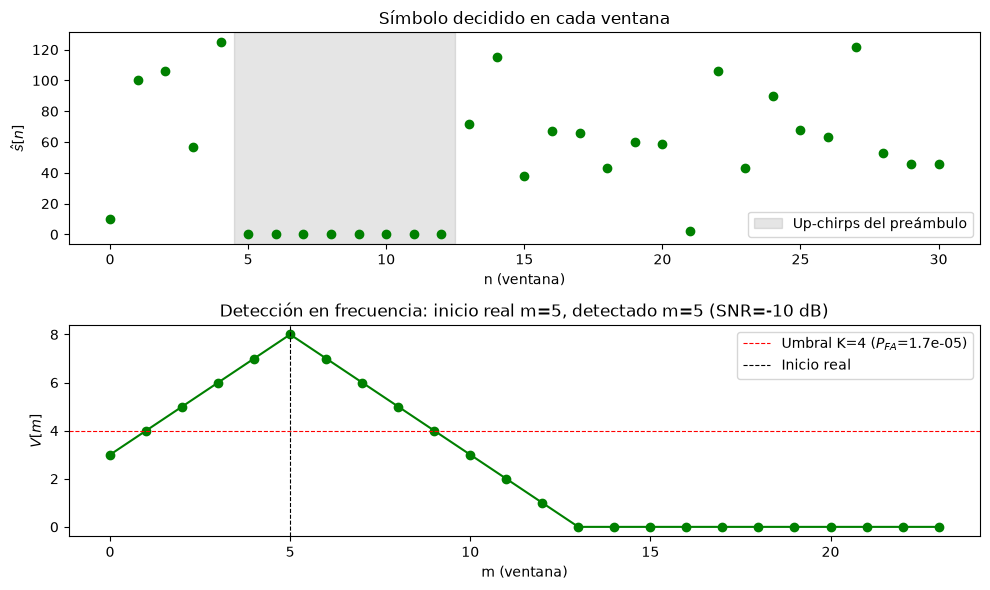

In [40]:
# Detección en frecuencia sobre el escenario
K = freq_threshold(P_FA, SF)  # Un test por ventana: misma P_FA por símbolo que en el tiempo
V = preamble_zero_count(r, SF)
start = detect_start(V, K)

# Símbolo decidido en cada ventana, para ver qué ventanas cuentan en V[m]
symbols_rx = demodulator(r[: r.size // M * M], SF)

plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(symbols_rx, "o", color="green")
plt.axvspan(gap - 0.5, gap + 7.5, color="k", alpha=0.1, label="Up-chirps del preámbulo")
plt.title("Símbolo decidido en cada ventana")
plt.xlabel("n (ventana)")
plt.ylabel("$\\hat{s}[n]$")
plt.legend()
plt.subplot(2, 1, 2)
plt.plot(V, marker="o", color="green")
plt.axhline(K, color="r", ls="--", lw=0.8, label=f"Umbral K={K} ($P_{{FA}}$={P_FA:.1e})")
plt.axvline(gap, color="k", ls="--", lw=0.8, label="Inicio real")
plt.title(f"Detección en frecuencia: inicio real m={gap}, detectado m={start} (SNR={SNR_dB} dB)")
plt.xlabel("m (ventana)")
plt.ylabel("$V[m]$")
plt.legend()
plt.tight_layout()
plt.show()

#### Performance en canal selectivo en frecuencia

Se estima la probabilidad de detectar el inicio correcto en función del SNR, en el canal selectivo y en el plano como referencia. El FER se guarda para la comparación final.

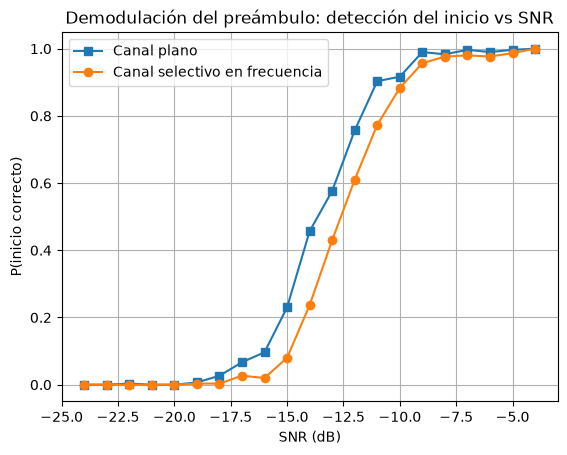

In [41]:
# Inicio correcto y FER en el canal plano y en el selectivo en frecuencia
p_freq_flat, fer_freq_flat = frame_rates(
    detect_freq, SNRs_rates_dB, h_flat, SF, B, P_FA, simulations
)
p_freq_sel, fer_freq_sel = frame_rates(
    detect_freq, SNRs_rates_dB, h_freq_sel, SF, B, P_FA, simulations
)

plt.plot(SNRs_rates_dB, p_freq_flat, marker="s", label="Canal plano")
plt.plot(SNRs_rates_dB, p_freq_sel, marker="o", label="Canal selectivo en frecuencia")
plt.title("Demodulación del preámbulo: detección del inicio vs SNR")
plt.xlabel("SNR (dB)")
plt.ylabel("P(inicio correcto)")
plt.grid(True)
plt.legend()
plt.show()

**Observaciones**:
- En el canal plano el inicio se encuentra en la mitad de las tramas cerca de $-14$ dB: cada ventana decide con el SNR de un solo símbolo.
- No llega al 100 % ni a SNR alto, por los empates descriptos arriba ($\approx 0.8\%$).
- El canal selectivo cuesta $\approx 1$ dB: el eco agrega a cada ventana una muestra del símbolo anterior, y solo el camino principal aporta al pico del bin 0.

### Comparación de los métodos

#### Detección del inicio

Se superponen las curvas de inicio correcto de los tres métodos: línea llena para el canal plano y punteada para el selectivo en frecuencia. Junto con la ROC, es la métrica para comparar los detectores: $1 - P(\text{inicio correcto})$ es exactamente la fracción de tramas que se pierden por la detección o la sincronización, ya que en esta simulación un inicio corrido una sola muestra invalida el *payload*.

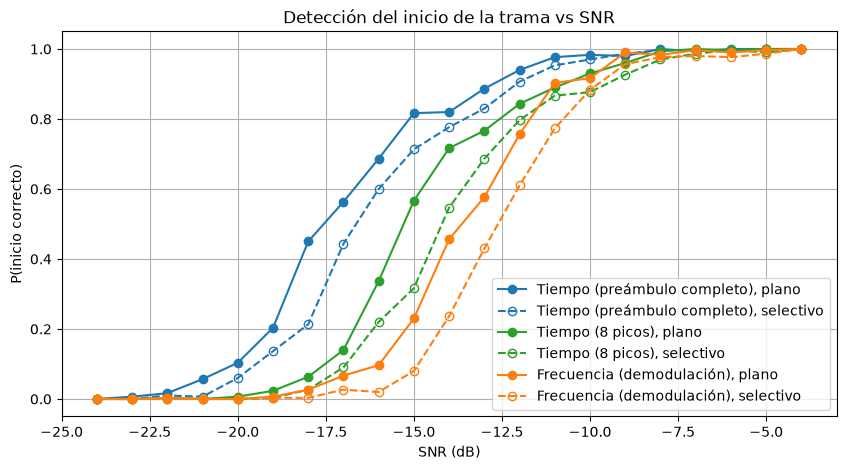

In [42]:
plt.figure(figsize=(10, 5))
for p_flat, p_sel, name, color in [
    (p_full_flat, p_full_sel, "Tiempo (preámbulo completo)", "C0"),
    (p_peaks_flat, p_peaks_sel, "Tiempo (8 picos)", "C2"),
    (p_freq_flat, p_freq_sel, "Frecuencia (demodulación)", "C1"),
]:
    plt.plot(SNRs_rates_dB, p_flat, color=color, marker="o", label=f"{name}, plano")
    plt.plot(
        SNRs_rates_dB,
        p_sel,
        color=color,
        marker="o",
        mfc="none",
        ls="--",
        label=f"{name}, selectivo",
    )
plt.title("Detección del inicio de la trama vs SNR")
plt.xlabel("SNR (dB)")
plt.ylabel("P(inicio correcto)")
plt.grid(True)
plt.legend()
plt.show()

**Observaciones**:
- Orden de los métodos, en ambos canales: correlación con el preámbulo completo, búsqueda de 8 picos y demodulación del preámbulo, con unos 2 dB entre cada uno (50 % de aciertos cerca de $-17.5$, $-15$ y $-14$ dB en el canal plano).
- **Integración coherente contra no coherente**: los dos métodos en el tiempo usan los mismos 8 picos de $y[k]$. Sumarlos antes del módulo (preámbulo completo) gana unos 2 dB frente a sumar sus energías (8 picos), a cambio de necesitar que la fase se mantenga durante el preámbulo.
- **Decisión blanda contra decisión dura**: los métodos en el tiempo conservan cuánto se parece cada posición a un *up-chirp*. La demodulación reduce cada ventana a "símbolo 0 o no", perdiendo información, y además necesita sincronía de símbolo.
- El canal selectivo desplaza todas las curvas $\approx 1$ dB sin cambiar el orden: solo el camino principal aporta a los picos.

#### Falsas alarmas

En las curvas de inicio correcto el silencio antes de la trama es corto y las falsas alarmas casi no penalizan, pero un receptor real pasa la mayor parte del tiempo escuchando solo ruido. Para validar que los umbrales de Neyman-Pearson cumplen la $P_{FA}$ pedida, se aplica cada método a una señal larga de solo ruido (20000 símbolos) y se mide la fracción de posiciones que superan el umbral.

En el punto de operación la $P_{FA}$ por muestra de los métodos en el tiempo es $\approx 1.3 \cdot 10^{-7}$: harían falta $\sim 10^9$ muestras para observar suficientes falsas alarmas. La distribución bajo $H_0$ es la misma para cualquier umbral, así que se valida el cálculo del umbral en un rango de $P_{FA}$ que se puede medir, de $10^{-1}$ a $10^{-5}$ por posición. En frecuencia solo se pueden medir los umbrales $K = 1$ y $K = 2$: $P_{FA}(3) \approx 2.6 \cdot 10^{-5}$ daría menos de una falsa alarma esperada en 20000 ventanas.

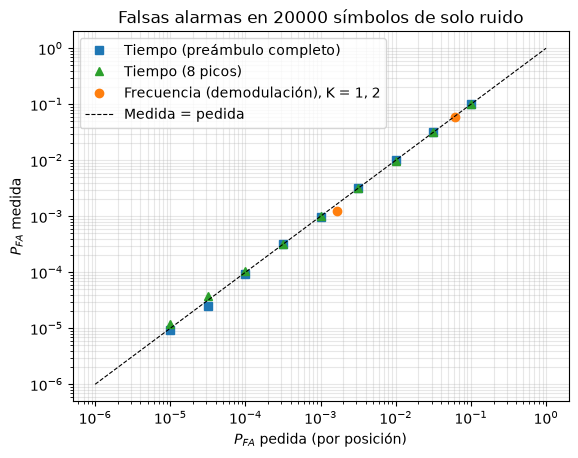

In [43]:
# Señal de solo ruido, con la potencia de ruido de -10 dB
num_noise_symbols = 20000
noise_power = power(preamble(SF, B)) / 10 ** (-10 / 10)
r_noise = noise_from_SNR(np.resize(preamble(SF, B), num_noise_symbols * M), -10)

# Estadístico de cada método en todas las posiciones
T_noise = preamble_correlation(r_noise, SF, B)
S_noise = peaks_statistic(r_noise, SF, B)
V_noise = preamble_zero_count(r_noise, SF)

# Fracción de posiciones que superan el umbral, para cada P_FA pedida (por posición)
P_FA_targets = np.logspace(-1, -5, 9)
P_FA_T = [np.mean(T_noise >= time_threshold(noise_power, p)) for p in P_FA_targets]
P_FA_S = [np.mean(S_noise >= peaks_threshold(noise_power, p)) for p in P_FA_targets]
Ks = np.array([1, 2])
P_FA_V_target = [zero_count_false_alarm(K, SF) for K in Ks]
P_FA_V = [np.mean(V_noise >= K) for K in Ks]

plt.loglog(P_FA_targets, P_FA_T, "s", color="C0", label="Tiempo (preámbulo completo)")
plt.loglog(P_FA_targets, P_FA_S, "^", color="C2", label="Tiempo (8 picos)")
plt.loglog(P_FA_V_target, P_FA_V, "o", color="C1", label="Frecuencia (demodulación), K = 1, 2")
plt.loglog([1e-6, 1], [1e-6, 1], color="k", ls="--", lw=0.8, label="Medida = pedida")
plt.title(f"Falsas alarmas en {num_noise_symbols} símbolos de solo ruido")
plt.xlabel("$P_{FA}$ pedida (por posición)")
plt.ylabel("$P_{FA}$ medida")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

**Observaciones**:
- Los tres métodos cumplen la $P_{FA}$ pedida: los puntos caen sobre la diagonal en todo el rango medible. Esto valida las distribuciones bajo $H_0$ (exponencial, Erlang y binomial) y el cálculo de los umbrales, y respalda usar la $P_{FA}$ teórica en el punto de operación y en la ROC, aunque estén fuera del rango medible.
- En $10^{-5}$ por posición la medición se dispersa: hay pocas falsas alarmas ($\approx 25$ esperadas) y llegan agrupadas. La plantilla es periódica cada $2^{SF}/2$ muestras, así que el estadístico en posiciones separadas medio símbolo usa casi las mismas muestras de ruido, y una falsa alarma suele repetirse en las posiciones vecinas.

#### Curva ROC

Las curvas de inicio correcto evalúan si se encuentra el inicio, lo que mezcla detección y localización. Para comparar los métodos solo como detectores se usa el test binario en una posición (una muestra en el tiempo, una ventana en frecuencia):

- $H_0$: los 8 símbolos a partir de la posición contienen solo ruido.
- $H_1$: la posición está alineada con el inicio del preámbulo.

Cada umbral define un punto de operación ($P_{FA}$, $P_D$) con $P_{FA} = P(\text{'}H_1\text{'} \mid H_0)$ y $P_D = P(\text{'}H_1\text{'} \mid H_1)$. La curva ROC (*Receiver Operating Characteristic*) recorre todos los umbrales y muestra el compromiso entre ambas probabilidades: subir el umbral reduce las falsas alarmas a costa de perder detecciones. El criterio de Neyman-Pearson elige el punto de la curva con la mayor $P_D$ que respeta la $P_{FA}$ tolerable. Un detector es mejor que otro si su curva queda por encima: para la misma $P_{FA}$, detecta más.

El receptor opera con $P_{FA}$ muy bajas, así que el eje de $P_{FA}$ es logarítmico. Además:

- **$P_{FA}$ por símbolo**: en el tiempo se prueban $2^{SF}$ posiciones por símbolo, así que la tasa de falsas alarmas por símbolo es $2^{SF}$ veces la $P_{FA}$ por muestra. Con este eje las tres curvas se comparan a la misma tasa de falsas alarmas, y los puntos de operación de Neyman-Pearson (estrellas) caen sobre la misma vertical.
- **$P_{FA}$ teórica**: con 2000 realizaciones bajo $H_0$ no se pueden estimar $P_{FA}$ menores que $1/2000$ por posición, y el punto de operación está muy por debajo. Pero bajo $H_0$ la distribución de cada estadístico es conocida (exponencial, Erlang y binomial): para cada $P_{FA}$ se calcula el umbral con las funciones de Neyman-Pearson de cada método, y solo se estima $P_D$, que sí se mide bien con pocas realizaciones. Las curvas empíricas (punteadas) validan las teóricas donde se pueden medir.

El estadístico $V[m]$ de la detección en frecuencia solo toma 9 valores (0 a 8 ventanas), así que su curva es una escalera: entre dos umbrales consecutivos, Neyman-Pearson se queda con el más alto que respeta la $P_{FA}$.

In [44]:
def roc(statistic_h0: np.ndarray, statistic_h1: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Curva ROC empírica a partir de realizaciones de un estadístico bajo cada hipótesis.

    Cada valor observado del estadístico es un umbral posible. Se decide H1 si el estadístico
    alcanza el umbral.

    Args:
        statistic_h0 (np.ndarray): Realizaciones del estadístico bajo H0.
        statistic_h1 (np.ndarray): Realizaciones del estadístico bajo H1.

    Returns:
        tuple[np.ndarray, np.ndarray]: P_FA y P_D para cada umbral, de mayor a menor umbral.
    """

    # Umbrales de mayor a menor. Un umbral infinito agrega el punto (0, 0): nunca se decide H1
    thresholds = np.concatenate(
        [[np.inf], np.unique(np.concatenate([statistic_h0, statistic_h1]))[::-1]]
    )

    # Fracción de realizaciones que alcanzan cada umbral (filas: realizaciones, columnas: umbrales)
    P_FA = np.mean(statistic_h0[:, None] >= thresholds, axis=0)
    P_D = np.mean(statistic_h1[:, None] >= thresholds, axis=0)

    return P_FA, P_D


def detection_statistics(
    SNR_dB: float, SF: int, B: float, simulations: int
) -> tuple[np.ndarray, ...]:
    """Simula realizaciones de los estadísticos de detección bajo cada hipótesis.

    Bajo H1 la posición 0 está alineada con el inicio del preámbulo; bajo H0 solo hay ruido.

    Args:
        SNR_dB (float): Relación señal-ruido en decibelios.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        simulations (int): Realizaciones por hipótesis.

    Returns:
        tuple[np.ndarray, ...]: Realizaciones de T[0], S[0] y V[0], cada una bajo H0 y H1.
    """

    T_h0, T_h1, S_h0, S_h1, V_h0, V_h1 = [], [], [], [], [], []
    for _ in range(simulations):
        # H1: trama sin silencio previo, la posición 0 está alineada con el inicio del preámbulo
        r1 = transmit_frame(np.random.randint(0, 2**SF, size=1), 0, SF, B, SNR_dB, np.array([1.0]))
        # H0: solo ruido, con la misma potencia que el ruido de la trama
        r0 = noise_from_SNR(preamble(SF, B), SNR_dB)
        # Estadístico de cada método en la posición 0
        T_h0.append(preamble_correlation(r0, SF, B)[0])
        T_h1.append(preamble_correlation(r1, SF, B)[0])
        S_h0.append(peaks_statistic(r0, SF, B)[0])
        S_h1.append(peaks_statistic(r1, SF, B)[0])
        V_h0.append(preamble_zero_count(r0, SF)[0])
        V_h1.append(preamble_zero_count(r1, SF)[0])

    return tuple(np.array(s) for s in (T_h0, T_h1, S_h0, S_h1, V_h0, V_h1))

In [45]:
# Tests: estadísticos separados dan un detector perfecto (pasa por el punto (0, 1))
P_FA_test, P_D_test = roc(np.array([0.0, 1.0]), np.array([2.0, 3.0]))
assert P_FA_test[0] == 0 and P_D_test[0] == 0  # Umbral infinito
assert np.any((P_FA_test == 0) & (P_D_test == 1))
assert P_FA_test[-1] == 1 and P_D_test[-1] == 1  # Umbral mínimo: siempre H1

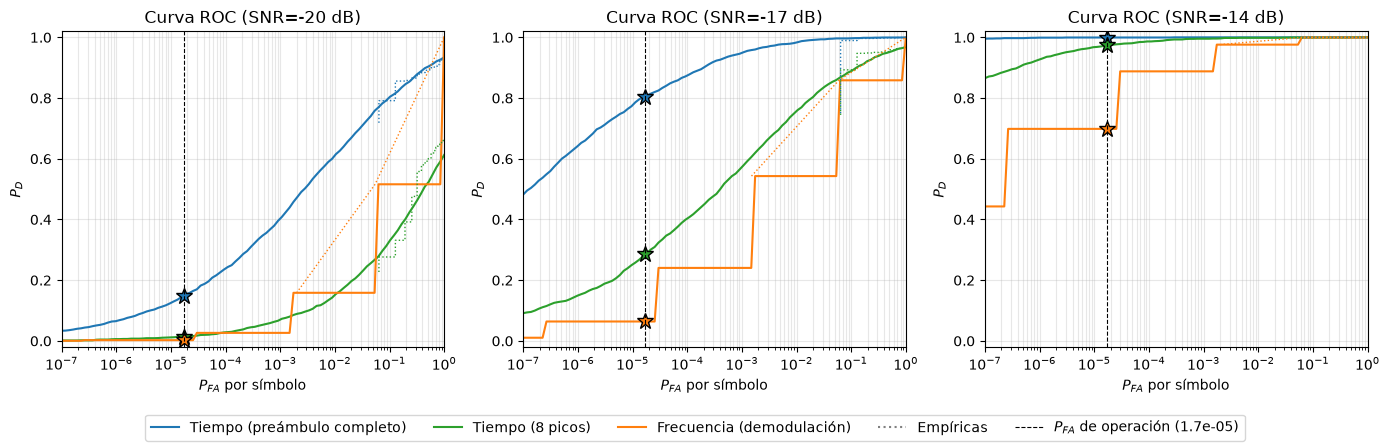

In [46]:
SF = 7
B = 125e3
M = 2**SF
SNRs_dB = [-20, -17, -14]  # Un gráfico por SNR, en el rango donde cambia la detección
simulations = 2000  # Realizaciones por hipótesis
P_FA_axis = np.logspace(-7, 0, 100)  # P_FA por símbolo

plt.figure(figsize=(14, 4.5))
for i, SNR_dB in enumerate(SNRs_dB):
    T_h0, T_h1, S_h0, S_h1, V_h0, V_h1 = detection_statistics(SNR_dB, SF, B, simulations)
    noise_power = power(preamble(SF, B)) / 10 ** (SNR_dB / 10)

    # Umbral de Neyman-Pearson de cada método para una P_FA por símbolo, como en detect_*
    # En el tiempo la P_FA por muestra es la P_FA por símbolo dividida por M
    methods = [
        ("Tiempo (preámbulo completo)", "C0", T_h1, lambda p: time_threshold(noise_power, p / M)),
        ("Tiempo (8 picos)", "C2", S_h1, lambda p: peaks_threshold(noise_power, p / M)),
        ("Frecuencia (demodulación)", "C1", V_h1, lambda p: freq_threshold(p, SF)),
    ]

    plt.subplot(1, len(SNRs_dB), i + 1)
    for name, color, h1, threshold in methods:
        # Curva teórica: P_FA exacta, P_D estimada con las realizaciones bajo H1
        plt.semilogx(
            P_FA_axis, [np.mean(h1 >= threshold(p)) for p in P_FA_axis], color=color, label=name
        )
        # Punto de operación de Neyman-Pearson
        plt.semilogx(P_FA, np.mean(h1 >= threshold(P_FA)), "*", color=color, ms=12, mec="k")

    # Curvas empíricas, en P_FA por símbolo: en el tiempo, M veces la P_FA por muestra
    for (P_FA_emp, P_D_emp), scale, color in [
        (roc(T_h0, T_h1), M, "C0"),
        (roc(S_h0, S_h1), M, "C2"),
        (roc(V_h0, V_h1), 1, "C1"),
    ]:
        nonzero = P_FA_emp > 0  # El eje logarítmico no puede mostrar P_FA = 0
        plt.semilogx(scale * P_FA_emp[nonzero], P_D_emp[nonzero], color=color, ls=":", lw=1)
    plt.plot([], [], color="gray", ls=":", label="Empíricas")

    plt.axvline(P_FA, color="k", ls="--", lw=0.8, label=f"$P_{{FA}}$ de operación ({P_FA:.1e})")
    plt.xlim(P_FA_axis[0], 1)
    plt.ylim(-0.02, 1.02)
    plt.title(f"Curva ROC (SNR={SNR_dB} dB)")
    plt.xlabel("$P_{FA}$ por símbolo")
    plt.ylabel("$P_D$")
    plt.grid(True, which="both", alpha=0.3)
# Una sola leyenda debajo de los gráficos, para no tapar las curvas
plt.gcf().legend(*plt.gca().get_legend_handles_labels(), loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

**Observaciones**:
- En el punto de operación ($P_{FA} \approx 1.7 \cdot 10^{-5}$ por símbolo, estrellas), a $-17$ dB la correlación con el preámbulo completo detecta con $P_D \approx 0.8$, la búsqueda de 8 picos con $\approx 0.3$ y la demodulación con $\approx 0.07$. A $-14$ dB los métodos en el tiempo ya detectan casi siempre y la demodulación llega a $\approx 0.7$.
- La correlación con el preámbulo completo queda por encima de las demás para cualquier $P_{FA}$ y SNR. Entre la búsqueda de 8 picos y la demodulación el orden depende de la $P_{FA}$: con $P_{FA}$ bajas gana la búsqueda de 8 picos, pero con $P_{FA}$ altas y SNR bajo la demodulación puede superarla. Los métodos en el tiempo prueban $2^{SF}$ posiciones por símbolo y necesitan un umbral más alto para la misma tasa de falsas alarmas; la demodulación prueba una sola, porque asume sincronía de símbolo.
- Bajar la $P_{FA}$ cuesta poco en los métodos en el tiempo: la $P_D$ cae en forma gradual. En la demodulación cae a escalones: con 9 umbrales posibles, la $P_{FA}$ de operación obliga a $K = 4$, con una $P_{FA}$ real unas 70 veces menor que la tolerada.
- Las curvas empíricas (punteadas) coinciden con las teóricas donde se pueden medir: $P_{FA}$ por símbolo mayores que $\approx 0.06$ en el tiempo ($2^{SF}/2000$) y que $\approx 2 \cdot 10^{-3}$ en frecuencia.
- El test en una posición funciona a menor SNR que la detección del inicio correcto (a $-17$ dB, $P_D \approx 0.8$ contra $\approx 0.55$ de inicio correcto con la correlación con el preámbulo completo). Encontrar el inicio exige además que la posición correcta supere a las vecinas, que se superponen parcialmente con el preámbulo.

#### Costo computacional

Se mide el tiempo de CPU que necesita cada método para procesar una trama (silencio, preámbulo y 16 símbolos de *payload*): el cálculo del estadístico y la decisión. Los umbrales quedan fuera de la medición, porque se calculan una vez por cada estimación de $\sigma^2$ y no por trama. Cada tiempo es el mínimo de varias mediciones, el menos afectado por otros procesos del sistema.

El costo esperado por muestra recibida, con $M = 2^{SF}$:

- **Preámbulo completo**: correlación directa con una plantilla de $8M$ muestras, $8M$ productos complejos por muestra.
- **8 picos**: correlación con un solo *up-chirp*, $M$ productos por muestra, más 8 sumas.
- **Frecuencia**: un producto por el *down-chirp* y una FFT de $M$ puntos por ventana ($M \log_2 M$ operaciones), $\approx \log_2 M$ operaciones por muestra. Evalúa una posición por ventana en lugar de una por muestra, porque asume sincronía de símbolo.

Los costos de los métodos en el tiempo crecen con $M$, y el de frecuencia casi no: la diferencia aumenta con el SF.

In [47]:
def cpu_time(fn: Callable[[], object]) -> float:
    """Tiempo de CPU de una llamada a `fn`, en segundos.

    Repite la medición 5 veces y devuelve la mínima: la menos afectada por otros procesos.

    Args:
        fn (Callable): Función sin argumentos a medir.

    Returns:
        float: Tiempo de CPU por llamada, en segundos.
    """

    timer = timeit.Timer(fn, timer=time.process_time)

    # Llamadas por medición, para que cada medición dure al menos 0.2 s
    number, _ = timer.autorange()

    return min(timer.repeat(repeat=5, number=number)) / number


def methods_cpu_time(SF: int, B: float, P_FA: float) -> tuple[float, float, float]:
    """Tiempo de CPU de cada método de detección para procesar una trama.

    Mide el estadístico y la decisión sobre una trama a -10 dB. Los umbrales se calculan antes.

    Args:
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        P_FA (float): Probabilidad de falsa alarma por símbolo.

    Returns:
        tuple[float, float, float]: Tiempo de CPU por trama, en segundos, de la correlación con el
        preámbulo completo, la búsqueda de 8 picos y la demodulación del preámbulo.
    """

    # Chips por símbolo
    M: int = 2**SF

    r = transmit_frame(np.random.randint(0, M, size=16), 5, SF, B, -10, np.array([1.0]))

    # Umbrales: se calculan una vez por estimación de sigma^2, fuera de la medición
    noise_power = power(preamble(SF, B)) / 10 ** (-10 / 10)
    eta = time_threshold(noise_power, P_FA / M)
    eta_S = peaks_threshold(noise_power, P_FA / M)
    K = freq_threshold(P_FA, SF)

    return (
        cpu_time(lambda: detect_start(preamble_correlation(r, SF, B), eta, 8 * M)),
        cpu_time(lambda: detect_start(peaks_statistic(r, SF, B), eta_S, 8 * M)),
        cpu_time(lambda: detect_start(preamble_zero_count(r, SF), K)),
    )

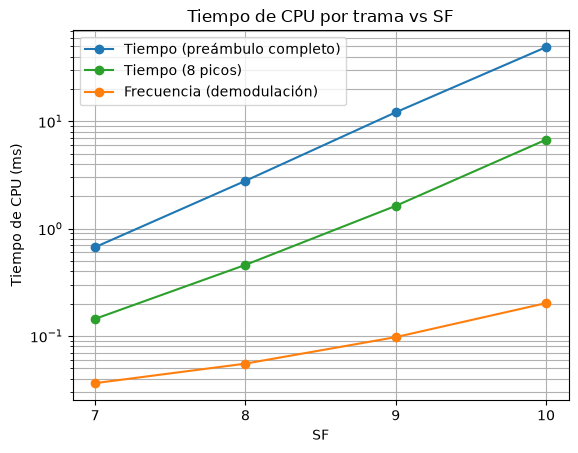

SF   preámbulo completo   8 picos   frecuencia   (veces el tiempo en frecuencia)
 7                   19       4.0            1
 8                   50       8.3            1
 9                  124      16.7            1
10                  243      33.3            1


In [48]:
# Tiempo de CPU por trama de cada método, para distintos SF
SFs = np.arange(7, 11)  # 7 a 10
cpu = np.array([methods_cpu_time(sf, B, P_FA) for sf in SFs])  # Una fila por SF

for j, (name, color) in enumerate(
    [
        ("Tiempo (preámbulo completo)", "C0"),
        ("Tiempo (8 picos)", "C2"),
        ("Frecuencia (demodulación)", "C1"),
    ]
):
    plt.semilogy(SFs, cpu[:, j] * 1e3, color=color, marker="o", label=name)
plt.xticks(SFs)
plt.title("Tiempo de CPU por trama vs SF")
plt.xlabel("SF")
plt.ylabel("Tiempo de CPU (ms)")
plt.grid(True, which="both")
plt.legend()
plt.show()

# Tiempo de cada método relativo a la demodulación del preámbulo, el más rápido
print("SF   preámbulo completo   8 picos   frecuencia   (veces el tiempo en frecuencia)")
for sf, (t_full, t_peaks, t_freq) in zip(SFs, cpu):
    print(f"{sf:2d}   {t_full / t_freq:18.0f}   {t_peaks / t_freq:7.1f}   {1:10.0f}")

**Observaciones**:
- La demodulación del preámbulo es la más barata en todos los SF: unas 4 veces más rápida que la búsqueda de 8 picos y unas 20 veces más rápida que la correlación con el preámbulo completo con $SF = 7$. Las diferencias crecen con el SF: con $SF = 10$ son unas 35 y 200 veces.
- La trama tiene $\approx 31 M$ muestras, así que el costo por trama de los métodos en el tiempo crece como $M^2$: $\times 4$ por cada SF, como se ve en la pendiente de sus curvas. El de frecuencia crece como $M \log_2 M$, apenas más que $\times 2$ por cada SF.
- La correlación con el preámbulo completo hace 8 veces más productos por muestra que la búsqueda de 8 picos, pero tarda entre 4.5 y 6 veces más, no 8: el tiempo medido incluye operaciones que no dependen del largo de la plantilla (el módulo, la suma de los 8 picos en la búsqueda de picos, la búsqueda del máximo).
- Es el compromiso entre performance y costo: el método que detecta a menor SNR es el más caro. `np.correlate` calcula la correlación en forma directa; con una correlación por FFT (*overlap-save*) los métodos en el tiempo bajarían a $O(\log M)$ operaciones por muestra, aunque seguirían evaluando todas las muestras en lugar de una por ventana.

#### Frame Error Rate (FER)

El FER mide el sistema completo: una trama se pierde si falla la detección del preámbulo o la demodulación del *payload*. Por eso no sirve para comparar los detectores entre sí, sino para responder otra pregunta: ¿la detección limita al sistema?

El ruido del preámbulo y el del *payload* son independientes (muestras disjuntas), así que, con $FER_{ideal}$ el FER con el inicio conocido (solo errores de demodulación):

$$
FER = 1 - P(\text{inicio correcto})\,(1 - FER_{ideal})
\qquad\Rightarrow\qquad
FER - FER_{ideal} = \left(1 - P(\text{inicio correcto})\right)(1 - FER_{ideal})
$$

La diferencia con la detección ideal solo cuenta las fallas de detección en tramas cuyo *payload* se habría decodificado bien: subestima las fallas de detección, y donde el *payload* falla igual ($FER_{ideal} \approx 1$) las oculta por completo. La cantidad de tramas perdidas por la detección es $1 - P(\text{inicio correcto})$, de la sección anterior.

Se compara el FER de los tres métodos con el de la detección ideal, en el canal plano (línea llena) y en el selectivo en frecuencia (punteada).

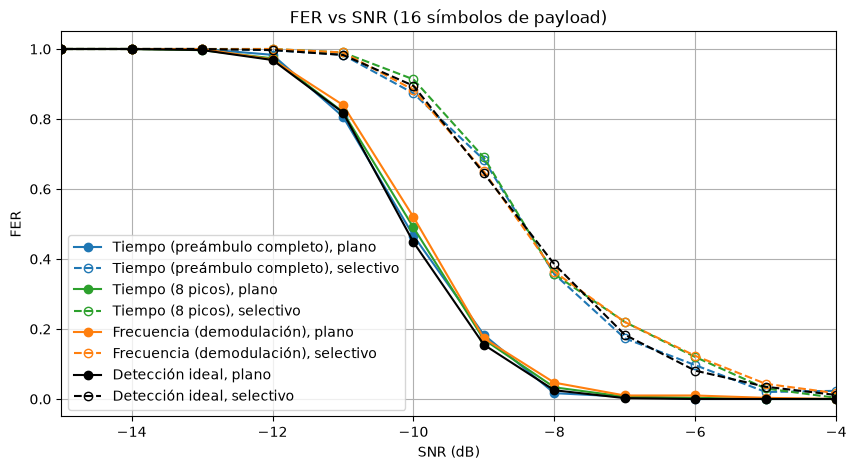

In [49]:
# Detección ideal como referencia: solo hay errores de demodulación
_, fer_ideal_flat = frame_rates(detect_ideal, SNRs_rates_dB, h_flat, SF, B, P_FA, simulations)
_, fer_ideal_sel = frame_rates(detect_ideal, SNRs_rates_dB, h_freq_sel, SF, B, P_FA, simulations)

# Escala lineal: en escala logarítmica no se verían los puntos con FER = 0
plt.figure(figsize=(10, 5))
for fer_flat, fer_sel, name, color in [
    (fer_full_flat, fer_full_sel, "Tiempo (preámbulo completo)", "C0"),
    (fer_peaks_flat, fer_peaks_sel, "Tiempo (8 picos)", "C2"),
    (fer_freq_flat, fer_freq_sel, "Frecuencia (demodulación)", "C1"),
    (fer_ideal_flat, fer_ideal_sel, "Detección ideal", "k"),
]:
    plt.plot(SNRs_rates_dB, fer_flat, color=color, marker="o", label=f"{name}, plano")
    plt.plot(
        SNRs_rates_dB,
        fer_sel,
        color=color,
        marker="o",
        mfc="none",
        ls="--",
        label=f"{name}, selectivo",
    )
plt.xlim(-15, -4)  # Por debajo de -15 dB se pierden todas las tramas
plt.title("FER vs SNR (16 símbolos de payload)")
plt.xlabel("SNR (dB)")
plt.ylabel("FER")
plt.grid(True)
plt.legend()
plt.show()

**Observaciones**:
- La detección no es el cuello de botella: en el canal plano los tres métodos encuentran el inicio en casi todas las tramas desde $-9$ dB, mientras que el *payload* necesita unos $-8$ dB para que los 16 símbolos se decidan bien. Las curvas de los tres métodos coinciden con la de detección ideal.
- Las curvas se superponen porque no hay ningún SNR donde se vean las diferencias entre detectores. Por debajo de $-9$ dB el *payload* falla igual y oculta las fallas de detección (aunque los métodos difieren en hasta 4 dB, ver la detección del inicio); por encima, los tres detectores ya aciertan casi siempre.
- El canal selectivo empeora el FER $\approx 2$ dB, también con detección ideal: la pérdida está en la demodulación del *payload* (el eco mezcla cada símbolo con el anterior), no en la detección.
- El preámbulo es más robusto que el *payload* porque la detección acumula información de 8 símbolos, mientras que el *payload* exige que todos sus símbolos se decidan bien. Para que el FER distinga los detectores, el *payload* tendría que ser más robusto que el preámbulo (por ejemplo, con codificación de canal o un preámbulo más corto).